In [131]:
print("hello world!")

hello world!



# ForeSight — Expense Classification

## 1. Introduction

This notebook focuses on developing the main Machine Learning
classification component of ForeSight.

The objective is to automatically predict the appropriate
expense category from transaction information.

### Objectives
1. Prepare the cleaned household transaction dataset.
2. Build features for expense classification.
3. Train and compare multiple classification algorithms.
4. Evaluate models using appropriate classification metrics.
5. Perform chronological validation.
6. Save the selected model for future application integration.

### Dataset
Cleaned Daily Household Transactions dataset.

### Initial Model Candidate
Linear Support Vector Machine (Linear SVM) with TF-IDF.

The model will be evaluated before final selection.



## 2. Import Libraries and Load Dataset


In [132]:

# ============================================================
# STEP 1 — IMPORT LIBRARIES AND LOAD DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load the cleaned dataset
DATA_PATH = Path("../data/processed/cleaned_household_transactions.csv")

df = pd.read_csv(DATA_PATH)

# Convert Date into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Display basic dataset information
print("Dataset loaded successfully!")
print("-" * 45)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
---------------------------------------------
Dataset shape: (2452, 9)

Column names:
['Date', 'Mode', 'Category', 'Subcategory', 'Note', 'Amount', 'Income/Expense', 'Currency', 'DateTime']

First five records:


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2452 entries, 0 to 2451
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            2452 non-null   datetime64[ns]
 1   Mode            2452 non-null   object        
 2   Category        2452 non-null   object        
 3   Subcategory     2452 non-null   object        
 4   Note            2452 non-null   object        
 5   Amount          2452 non-null   float64       
 6   Income/Expense  2452 non-null   object        
 7   Currency        2452 non-null   object        
 8   DateTime        2452 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(7)
memory usage: 172.5+ KB



## 3. Prepare the Household Consumption Dataset

In this section, we will:
1. Select expense transactions only.
2. Exclude financial activities such as investments and transfers.
3. Remove identified non-consumption transactions.
4. Standardize subcategory names.
5. Verify the final classification dataset.


In [133]:

# ============================================================
# STEP 2 — PREPARE HOUSEHOLD CONSUMPTION DATASET
# ============================================================

# 1. Select expense transactions only

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

print("Total expense transactions:", len(expense_df))


# 2. Define financial categories to exclude

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]


# 3. Define non-consumption transaction notes to exclude

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]


# 4. Create the household consumption dataset

household_consumption_df = expense_df[
    (~expense_df["Category"].isin(financial_categories_strict)) &
    (~expense_df["Note"].isin(excluded_notes))
].copy()


# 5. Standardize subcategory names

household_consumption_df["Subcategory"] = (
    household_consumption_df["Subcategory"]
    .astype(str)
    .str.strip()
    .str.title()
)


# 6. Display final dataset information

print("\n" + "=" * 55)
print("HOUSEHOLD CONSUMPTION DATASET")
print("=" * 55)

print("Total transactions:", len(household_consumption_df))

print(
    "Total consumption amount: ₹",
    round(household_consumption_df["Amount"].sum(), 2)
)

print(
    "Number of categories:",
    household_consumption_df["Category"].nunique()
)

print(
    "Date range:",
    household_consumption_df["Date"].min(),
    "to",
    household_consumption_df["Date"].max()
)

print("\nCategory distribution:")

display(
    household_consumption_df["Category"]
    .value_counts()
)

print("\nFirst five records:")

display(household_consumption_df.head())


# 7. Final data quality check

print("\nMissing values:")

display(household_consumption_df.isnull().sum())

print("\nHousehold consumption dataset prepared successfully!")


Total expense transactions: 2173

HOUSEHOLD CONSUMPTION DATASET
Total transactions: 1996
Total consumption amount: ₹ 936993.63
Number of categories: 23
Date range: 2015-01-01 00:00:00 to 2018-12-09 00:00:00

Category distribution:


Category
Food                   906
Transportation         307
Household              176
subscription           143
Other                  111
Health                  94
Family                  71
Apparel                 47
Gift                    30
Beauty                  22
Education               18
maid                    17
Festivals               16
Culture                 11
Tourism                  5
Cook                     4
Grooming                 4
Rent                     4
water (jar /tanker)      3
Self-development         2
Documents                2
garbage disposal         2
Social Life              1
Name: count, dtype: int64


First five records:


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency,DateTime
0,2018-09-20,Cash,Transportation,Train,2 Place 5 to Place 0,30.0,Expense,INR,2018-09-20 12:04:08
1,2018-09-20,Cash,Food,Snacks,Idli medu Vada mix 2 plates,60.0,Expense,INR,2018-09-20 12:03:15
2,2018-09-19,Saving Bank account 1,subscription,Netflix,1 month subscription,199.0,Expense,INR,2018-09-19 00:00:00
3,2018-09-17,Saving Bank account 1,subscription,Mobile Service Provider,Data booster pack,19.0,Expense,INR,2018-09-17 23:41:17
4,2018-09-16,Cash,Festivals,Ganesh Pujan,Ganesh idol,251.0,Expense,INR,2018-09-16 17:15:08



Missing values:


Date              0
Mode              0
Category          0
Subcategory       0
Note              0
Amount            0
Income/Expense    0
Currency          0
DateTime          0
dtype: int64


Household consumption dataset prepared successfully!


## 4. Data Quality and Category Distribution

Dataset Shape: (1996, 9)

Missing Values:


Date              0
Mode              0
Category          0
Subcategory       0
Note              0
Amount            0
Income/Expense    0
Currency          0
DateTime          0
dtype: int64


Duplicate Records: 0

Expense Category Distribution:


Category
Food                   906
Transportation         307
Household              176
subscription           143
Other                  111
Health                  94
Family                  71
Apparel                 47
Gift                    30
Beauty                  22
Education               18
maid                    17
Festivals               16
Culture                 11
Tourism                  5
Cook                     4
Grooming                 4
Rent                     4
water (jar /tanker)      3
Self-development         2
Documents                2
garbage disposal         2
Social Life              1
Name: count, dtype: int64

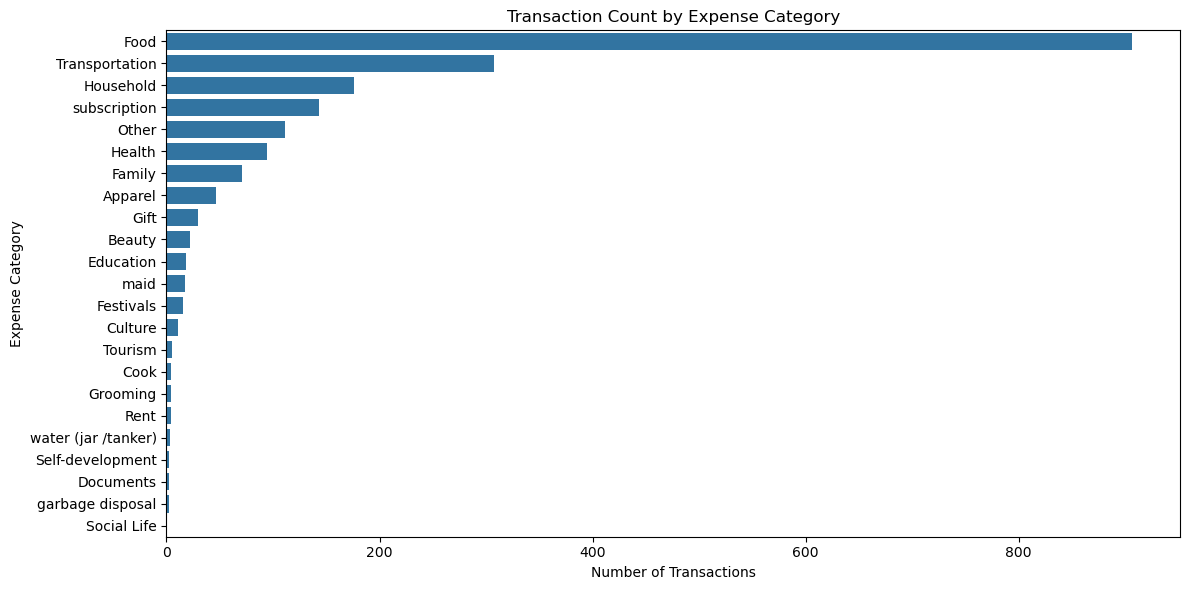


Transaction Amount Statistics:


count     1996.000000
mean       469.435686
std       2240.267117
min          2.000000
25%         30.000000
50%         70.000000
75%        251.000000
max      50000.000000
Name: Amount, dtype: float64


Data quality check completed!


In [134]:

# ============================================================
# STEP 3 — DATA QUALITY CHECK
# ============================================================

# 1. Dataset overview
print("Dataset Shape:", household_consumption_df.shape)

# 2. Missing values
print("\nMissing Values:")
display(household_consumption_df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate Records:",
      household_consumption_df.duplicated().sum())

# 4. Category distribution
print("\nExpense Category Distribution:")
category_counts = household_consumption_df["Category"].value_counts()
display(category_counts)

# 5. Category distribution visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Transaction Count by Expense Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Expense Category")
plt.tight_layout()
plt.show()

# 6. Amount statistics
print("\nTransaction Amount Statistics:")
display(household_consumption_df["Amount"].describe())

print("\nData quality check completed!")


## 5. Feature Engineering

Preparing transaction features for expense classification.

In [135]:

# ============================================================
# STEP 4 — FEATURE ENGINEERING
# ============================================================

# Create an independent ML dataset
ml_df = household_consumption_df[
    ["Date", "Mode", "Amount", "Note", "Category"]
].copy()

# Convert amount into numeric format
ml_df["Amount"] = pd.to_numeric(
    ml_df["Amount"], errors="coerce"
)

# Handle missing transaction descriptions
ml_df["Note"] = ml_df["Note"].fillna("").astype(str)

# Extract useful date features
ml_df["DayOfWeek"] = ml_df["Date"].dt.dayofweek
ml_df["Month"] = ml_df["Date"].dt.month

# Remove records with missing target or invalid date/amount
ml_df = ml_df.dropna(
    subset=["Date", "Amount", "Category", "Mode"]
).copy()

# Display prepared features
print("Feature engineering completed!")
print("\nDataset shape:", ml_df.shape)

print("\nSelected features:")
display(ml_df.head())

print("\nFeature columns:")
print(ml_df.columns.tolist())


Feature engineering completed!

Dataset shape: (1996, 7)

Selected features:


,Date,Mode,Amount,Note,Category,DayOfWeek,Month
0,2018-09-20,Cash,30.0,2 Place 5 to Place 0,Transportation,3,9
1,2018-09-20,Cash,60.0,Idli medu Vada mix 2 plates,Food,3,9
2,2018-09-19,Saving Bank account 1,199.0,1 month subscription,subscription,2,9
3,2018-09-17,Saving Bank account 1,19.0,Data booster pack,subscription,0,9
4,2018-09-16,Cash,251.0,Ganesh idol,Festivals,6,9



Feature columns:
['Date', 'Mode', 'Amount', 'Note', 'Category', 'DayOfWeek', 'Month']


## 6. Define Features and Target

In [136]:

# ============================================================
# STEP 5 — DEFINE FEATURES (X) AND TARGET (y)
# ============================================================

# Input features
X = ml_df[
    ["Note", "Amount", "Mode", "DayOfWeek", "Month"]
].copy()

# Target variable
y = ml_df["Category"].copy()

# Display results
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nInput features:")
display(X.head())

print("\nTarget categories:")
display(y.head())

print("\nNumber of unique categories:", y.nunique())


Features (X) shape: (1996, 5)
Target (y) shape: (1996,)

Input features:


,Note,Amount,Mode,DayOfWeek,Month
0,2 Place 5 to Place 0,30.0,Cash,3,9
1,Idli medu Vada mix 2 plates,60.0,Cash,3,9
2,1 month subscription,199.0,Saving Bank account 1,2,9
3,Data booster pack,19.0,Saving Bank account 1,0,9
4,Ganesh idol,251.0,Cash,6,9



Target categories:


0    Transportation
1              Food
2      subscription
3      subscription
4         Festivals
Name: Category, dtype: object


Number of unique categories: 23


## 7. Chronological Train-Test Split

In [137]:

# ============================================================
# STEP 6 — CHRONOLOGICAL TRAIN-TEST SPLIT
# ============================================================

# Sort transactions by date
ml_df = ml_df.sort_values("Date").reset_index(drop=True)

# Select the 80% cutoff position
split_index = int(len(ml_df) * 0.80)

# Determine cutoff date
cutoff_date = ml_df.loc[split_index, "Date"]

# Split using dates
train_df = ml_df[ml_df["Date"] <= cutoff_date].copy()
test_df = ml_df[ml_df["Date"] > cutoff_date].copy()

# Separate features and target again
X_train = train_df[
    ["Note", "Amount", "Mode", "DayOfWeek", "Month"]
]
y_train = train_df["Category"]

X_test = test_df[
    ["Note", "Amount", "Mode", "DayOfWeek", "Month"]
]
y_test = test_df["Category"]

# Display results
print("Cutoff Date:", cutoff_date)

print("\nTraining transactions:", len(X_train))
print("Testing transactions:", len(X_test))

print("\nTraining date range:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting date range:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

print("\nTraining categories:", y_train.nunique())
print("Testing categories:", y_test.nunique())


Cutoff Date: 2018-03-18 00:00:00

Training transactions: 1602
Testing transactions: 394

Training date range:
2015-01-01 00:00:00 to 2018-03-18 00:00:00

Testing date range:
2018-03-20 00:00:00 to 2018-12-09 00:00:00

Training categories: 22
Testing categories: 17


## 8. Training and Testing Category Validation

In [138]:

# ============================================================
# STEP 7 — CATEGORY ELIGIBILITY CHECK
# ============================================================

train_categories = set(y_train.unique())
test_categories = set(y_test.unique())

common_categories = train_categories & test_categories
unseen_categories = test_categories - train_categories
train_only_categories = train_categories - test_categories

print("Categories in training:", len(train_categories))
print("Categories in testing:", len(test_categories))
print("Categories present in both:", len(common_categories))

print("\nCategories unseen during training:")
print(sorted(unseen_categories))

print("\nCategories present only in training:")
print(sorted(train_only_categories))

print("\nCategory eligibility check completed!")


Categories in training: 22
Categories in testing: 17
Categories present in both: 16

Categories unseen during training:
['Documents']

Categories present only in training:
['Cook', 'Grooming', 'Rent', 'Social Life', 'garbage disposal', 'water (jar /tanker)']

Category eligibility check completed!


## 9. Build the Preprocessing and Classification Pipeline

In [139]:

# ============================================================
# STEP 8 — BUILD ML PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import LinearSVC

# 1. Process transaction descriptions
text_transformer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

# 2. Process payment mode
mode_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# 3. Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 4. Combine all preprocessing techniques
preprocessor = ColumnTransformer(
    transformers=[
        ("text", text_transformer, "Note"),
        ("mode", mode_transformer, ["Mode"]),
        ("numeric", numeric_transformer,
         ["Amount", "DayOfWeek", "Month"])
    ]
)

# 5. Create the complete ML pipeline
classification_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

print("Preprocessing pipeline created successfully!")
print("\nModel:", classification_model)


Preprocessing pipeline created successfully!

Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  TfidfVectorizer(max_features=10000,
                                                                  min_df=2,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  strip_accents='unicode',
                                                                  sublinear_tf=True),
                                                  'Note'),
                                                 ('mode',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Mode']),
                                                 ('numeric',
                       

## 10. Train the Linear SVM Classification Model

In [140]:

# ============================================================
# STEP 9 — TRAIN LINEAR SVM MODEL
# ============================================================

# Train the model using training data
classification_model.fit(X_train, y_train)

print("Linear SVM model trained successfully!")

# Generate predictions on test data
y_pred = classification_model.predict(X_test)

print("\nPredictions generated successfully!")

# Evaluate only categories known during training
supported_mask = y_test.isin(train_categories)

y_test_supported = y_test[supported_mask]
y_pred_supported = y_pred[supported_mask]

print("\nTotal test transactions:", len(y_test))
print("Supported test transactions:", len(y_test_supported))
print("Unsupported test transactions:", (~supported_mask).sum())


Linear SVM model trained successfully!

Predictions generated successfully!

Total test transactions: 394
Supported test transactions: 392
Unsupported test transactions: 2


## 11. Evaluate Linear SVM Performance

In [141]:

# ============================================================
# STEP 10 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_supported, y_pred_supported)

precision = precision_score(
    y_test_supported, y_pred_supported,
    average="macro", zero_division=0
)

recall = recall_score(
    y_test_supported, y_pred_supported,
    average="macro", zero_division=0
)

f1 = f1_score(
    y_test_supported, y_pred_supported,
    average="macro", zero_division=0
)

# Display results
print("LINEAR SVM — CHRONOLOGICAL EVALUATION")
print("=" * 50)

print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"Macro F1:  {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test_supported,
        y_pred_supported,
        zero_division=0
    )
)


LINEAR SVM — CHRONOLOGICAL EVALUATION
Accuracy:  0.7730 (77.30%)
Precision: 0.4204
Recall:    0.4623
Macro F1:  0.4329

Detailed Classification Report:
                     precision    recall  f1-score   support

            Apparel       0.77      0.77      0.77        13
             Beauty       0.67      1.00      0.80         4
               Cook       0.00      0.00      0.00         0
            Culture       0.33      0.67      0.44         3
          Education       1.00      1.00      1.00         3
             Family       0.00      0.00      0.00        19
          Festivals       0.50      0.67      0.57         3
               Food       0.91      0.90      0.91       188
               Gift       0.75      1.00      0.86         3
             Health       0.71      0.59      0.65        17
          Household       0.69      0.50      0.58        50
              Other       0.13      0.29      0.18         7
   Self-development       0.00      0.00      0.00    

## 12. Confusion Matrix Analysis

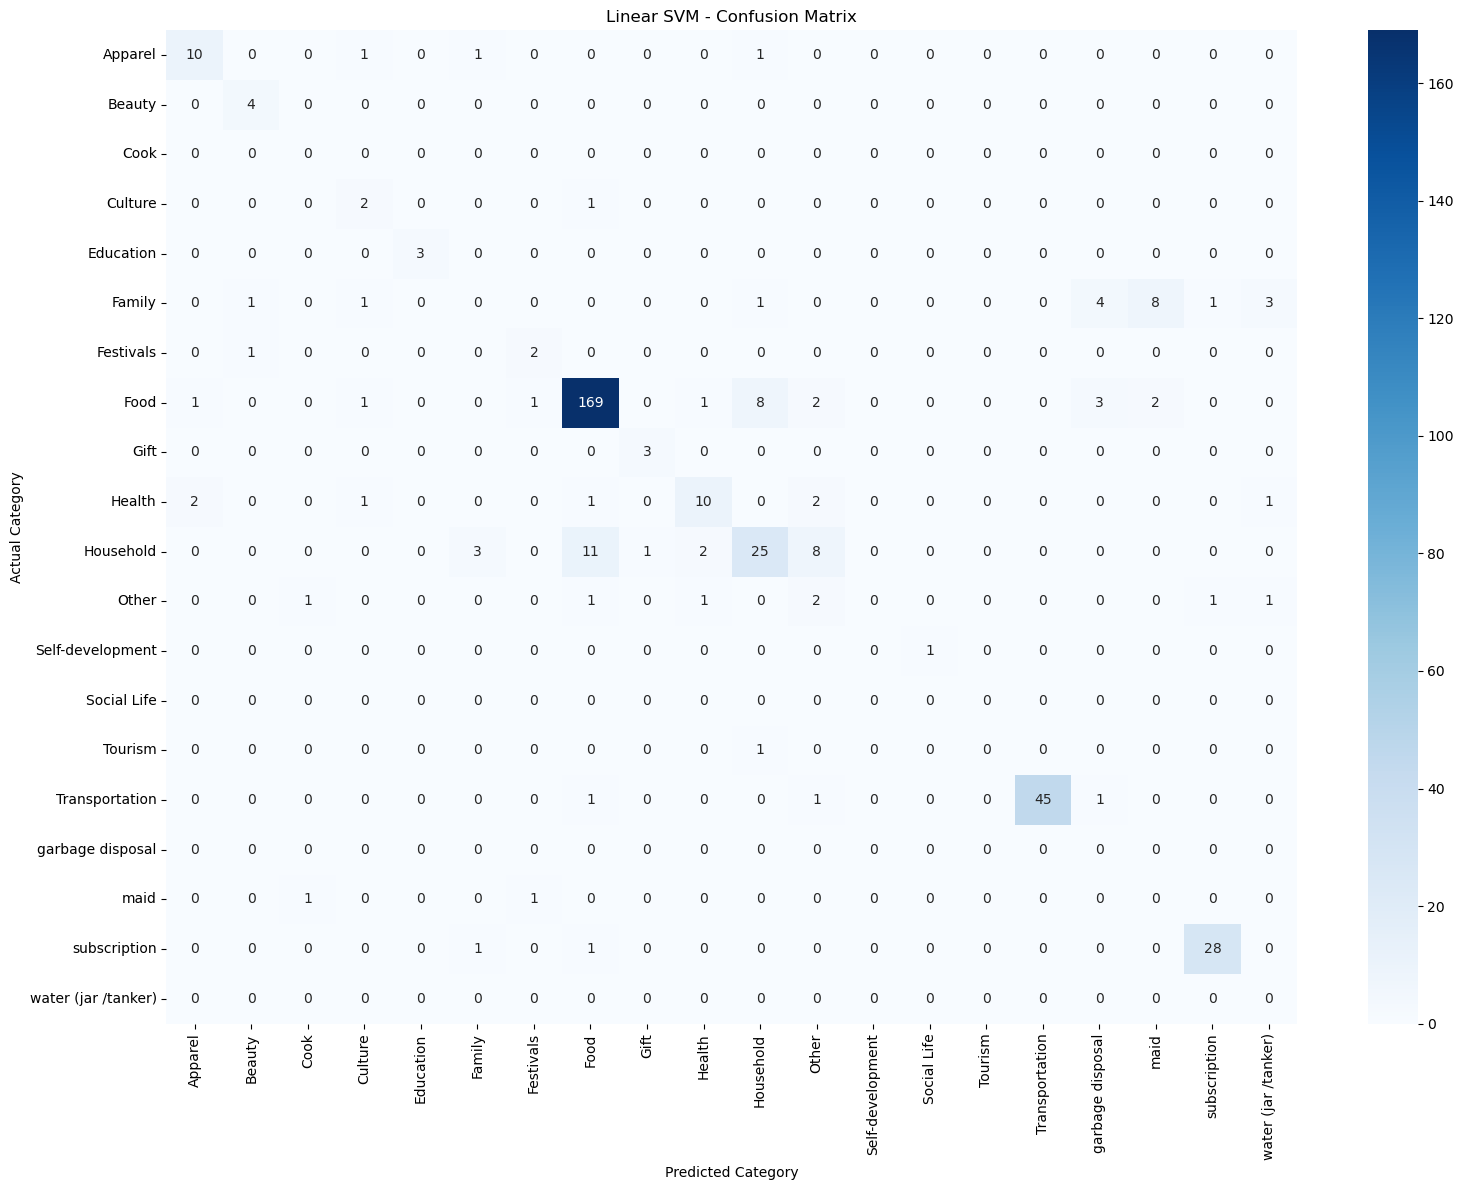

Confusion matrix generated successfully!


In [142]:

# ============================================================
# STEP 11 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix

# Include actual and predicted categories
labels = sorted(
    set(y_test_supported) | set(y_pred_supported)
)

# Calculate confusion matrix
cm = confusion_matrix(
    y_test_supported,
    y_pred_supported,
    labels=labels
)

# Visualize
plt.figure(figsize=(16, 12))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Confusion matrix generated successfully!")


## 13. Category-wise Performance Analysis?

In [143]:

# ============================================================
# STEP 12 — CATEGORY-WISE PERFORMANCE
# ============================================================

from sklearn.metrics import precision_recall_fscore_support

# Calculate metrics for each actual test category
category_metrics = precision_recall_fscore_support(
    y_test_supported,
    y_pred_supported,
    labels=sorted(y_test_supported.unique()),
    zero_division=0
)

category_performance = pd.DataFrame({
    "Category": sorted(y_test_supported.unique()),
    "Precision": category_metrics[0],
    "Recall": category_metrics[1],
    "F1_Score": category_metrics[2],
    "Support": category_metrics[3]
})

# Sort from weakest to strongest
category_performance = category_performance.sort_values(
    "F1_Score"
)

display(category_performance)

print("\nWeakest categories:")
display(category_performance.head(5))

print("\nStrongest categories:")
display(category_performance.tail(5))


,Category,Precision,Recall,F1_Score,Support
4,Family,0.000000,0.000000,0.000000,19
14,maid,0.000000,0.000000,0.000000,2
12,Tourism,0.000000,0.000000,0.000000,1
11,Self-development,0.000000,0.000000,0.000000,1
10,Other,0.133333,0.285714,0.181818,7
2,Culture,0.333333,0.666667,0.444444,3
5,Festivals,0.500000,0.666667,0.571429,3
9,Household,0.694444,0.500000,0.581395,50
8,Health,0.714286,0.588235,0.645161,17
0,Apparel,0.769231,0.769231,0.769231,13



Weakest categories:


,Category,Precision,Recall,F1_Score,Support
4,Family,0.000000,0.000000,0.000000,19
14,maid,0.000000,0.000000,0.000000,2
12,Tourism,0.000000,0.000000,0.000000,1
11,Self-development,0.000000,0.000000,0.000000,1
10,Other,0.133333,0.285714,0.181818,7



Strongest categories:


,Category,Precision,Recall,F1_Score,Support
7,Gift,0.750000,1.000000,0.857143,3
6,Food,0.913514,0.898936,0.906166,188
15,subscription,0.933333,0.933333,0.933333,30
13,Transportation,1.000000,0.937500,0.967742,48
3,Education,1.000000,1.000000,1.000000,3


## 14. Incorrect Prediction Analysis

In [144]:

# ============================================================
# STEP 13 — INVESTIGATE INCORRECT PREDICTIONS
# ============================================================

# Create an audit table
prediction_audit = X_test.copy()

prediction_audit["Actual_Category"] = y_test
prediction_audit["Predicted_Category"] = pd.Series(
    y_pred, index=y_test.index
)

prediction_audit["Correct"] = (
    prediction_audit["Actual_Category"] ==
    prediction_audit["Predicted_Category"]
)

# Extract incorrect predictions
incorrect_predictions = prediction_audit[
    ~prediction_audit["Correct"]
].copy()

# Display results
print("Total incorrect predictions:", len(incorrect_predictions))

print("\nFirst 20 incorrect transactions:")

display(
    incorrect_predictions[
        ["Note", "Amount", "Mode",
         "Actual_Category", "Predicted_Category"]
    ].head(20)
)

# Most common classification mistakes
print("\nMost common classification mistakes:")

mistake_summary = (
    incorrect_predictions
    .groupby(["Actual_Category", "Predicted_Category"])
    .size()
    .sort_values(ascending=False)
)

display(mistake_summary.head(15))


Total incorrect predictions: 91

First 20 incorrect transactions:


,Note,Amount,Mode,Actual_Category,Predicted_Category
1603,No Note,17.0,Saving Bank account 2,Other,Cook
1608,No Note,50.0,Cash,Family,garbage disposal
1618,Finding next Job,100.0,Cash,Culture,Food
1620,French crossiant,80.0,Credit Card,Food,Culture
1638,Cockroach injection,270.0,Cash,Household,Food
1640,Aadhar Address Change,50.0,Saving Bank account 1,Documents,Family
1644,No Note,450.0,Cash,Family,maid
1650,No Note,350.0,Cash,Family,maid
1652,Family Thyroid Test + CBC,700.0,Cash,Health,Apparel
1657,"Vessels for sugar, coffee and tea",799.0,Credit Card,Household,Gift



Most common classification mistakes:


Actual_Category  Predicted_Category 
Household        Food                   11
Family           maid                    8
Food             Household               8
Household        Other                   8
Family           garbage disposal        4
                 water (jar /tanker)     3
Household        Family                  3
Food             garbage disposal        3
Health           Other                   2
Food             maid                    2
Health           Apparel                 2
Household        Health                  2
Food             Other                   2
Apparel          Household               1
Festivals        Beauty                  1
dtype: int64

## 15. Error Analysis — Transaction Description Quality

In [145]:

# ============================================================
# STEP 14 — DESCRIPTION QUALITY IN PREDICTION ERRORS
# ============================================================

audit = incorrect_predictions.copy()

# Identify missing or unhelpful descriptions
unhelpful_notes = [
    "", "no note", "no description", "nan"
]

audit["Description_Status"] = np.where(
    audit["Note"].fillna("")
    .astype(str).str.strip().str.lower()
    .isin(unhelpful_notes),
    "No Useful Description",
    "Description Available"
)

print("Description quality among incorrect predictions:")
display(audit["Description_Status"].value_counts())

print("\nDescription quality by actual category:")
display(
    pd.crosstab(
        audit["Actual_Category"],
        audit["Description_Status"]
    )
)

print("\nError analysis completed!")


Description quality among incorrect predictions:


Description_Status
Description Available    64
No Useful Description    27
Name: count, dtype: int64


Description quality by actual category:


Description_Status,Description Available,No Useful Description
Actual_Category,,
Apparel,3,0
Culture,1,0
Documents,2,0
Family,3,16
Festivals,1,0
Food,14,5
Health,6,1
Household,24,1
Other,4,1



Error analysis completed!


## 16. Top Classification Confusion Analysis

,Actual_Category,Predicted_Category,Mistake_Count
28,Household,Food,11
10,Family,maid,8
18,Food,Household,8
31,Household,Other,8
9,Family,garbage disposal,4
12,Family,water (jar /tanker),3
27,Household,Family,3
20,Food,garbage disposal,3
25,Health,Other,2
21,Food,maid,2


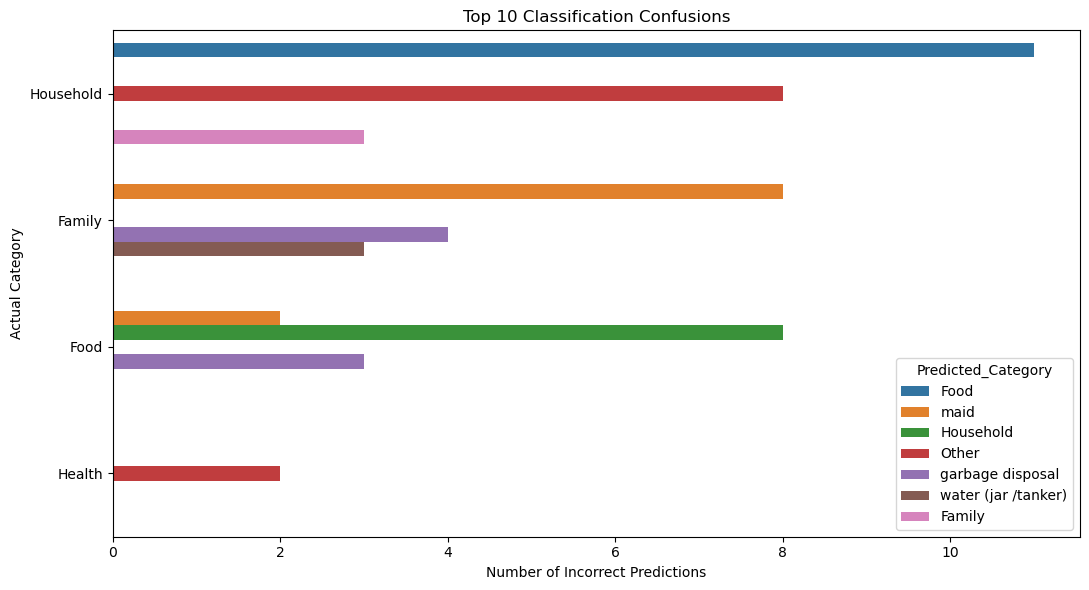

In [146]:

# ============================================================
# STEP 15 — TOP CLASSIFICATION CONFUSIONS
# ============================================================

top_mistakes = (
    incorrect_predictions
    .groupby(["Actual_Category", "Predicted_Category"])
    .size()
    .reset_index(name="Mistake_Count")
    .sort_values("Mistake_Count", ascending=False)
    .head(10)
)

display(top_mistakes)

# Visualize the most frequent mistakes
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_mistakes,
    x="Mistake_Count",
    y="Actual_Category",
    hue="Predicted_Category"
)

plt.title("Top 10 Classification Confusions")
plt.xlabel("Number of Incorrect Predictions")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()


## 17. Detailed Investigation of Top Confusion Pairs

In [147]:

# ============================================================
# STEP 16 — DETAILED CONFUSION INVESTIGATION
# ============================================================

confusion_pairs = [
    ("Household", "Food"),
    ("Family", "maid"),
    ("Food", "Household")
]

for actual, predicted in confusion_pairs:

    print("\n" + "=" * 55)
    print(f"ACTUAL: {actual} | PREDICTED: {predicted}")
    print("=" * 55)

    examples = incorrect_predictions[
        (incorrect_predictions["Actual_Category"] == actual) &
        (incorrect_predictions["Predicted_Category"] == predicted)
    ]

    display(
        examples[
            ["Note", "Amount", "Mode",
             "Actual_Category", "Predicted_Category"]
        ]
    )



ACTUAL: Household | PREDICTED: Food


,Note,Amount,Mode,Actual_Category,Predicted_Category
1638,Cockroach injection,270.0,Cash,Household,Food
1665,Cockroach injection,270.0,Saving Bank account 1,Household,Food
1749,Soap + dahya pav kg,75.0,Cash,Household,Food
1754,5 litres can Distilled water,100.0,Saving Bank account 1,Household,Food
1800,Mouse pad,100.0,Cash,Household,Food
1806,3 bulbs 3 pencil cells,270.0,Cash,Household,Food
1807,Tulsi plant+ pot,70.0,Cash,Household,Food
1816,Pav kg chana dal,24.0,Cash,Household,Food
1867,Harpik 1L,165.0,Cash,Household,Food
1889,5 litres can Distilled water,100.0,Cash,Household,Food



ACTUAL: Family | PREDICTED: maid


,Note,Amount,Mode,Actual_Category,Predicted_Category
1644,No Note,450.0,Cash,Family,maid
1650,No Note,350.0,Cash,Family,maid
1683,No Note,1000.0,Cash,Family,maid
1687,No Note,500.0,Cash,Family,maid
1699,No Note,500.0,Cash,Family,maid
1709,No Note,600.0,Cash,Family,maid
1854,No Note,200.0,Cash,Family,maid
1929,No Note,1000.0,Cash,Family,maid



ACTUAL: Food | PREDICTED: Household


,Note,Amount,Mode,Actual_Category,Predicted_Category
1685,Noodles packet,30.0,Cash,Food,Household
1692,Toast packet,45.0,Cash,Food,Household
1697,1 packet,69.0,Saving Bank account 1,Food,Household
1843,Toast packet,45.0,Cash,Food,Household
1849,Toast packet,40.0,Cash,Food,Household
1937,Toast packet,45.0,Cash,Food,Household
1940,Toast packet,20.0,Cash,Food,Household
1973,1 packet,20.0,Cash,Food,Household



## 18. Classification Error Analysis — Final Findings

### Key Findings

1. Household and Food are frequently confused.
2. Family transactions often have missing descriptions.
3. Generic descriptions reduce classification reliability.
4. Rare categories have limited training examples.
5. Overall accuracy does not reflect equal performance across categories.

### Improvement Strategy

1. Review category consistency.
2. Improve handling of missing transaction descriptions.
3. Introduce an uncertain-prediction fallback.
4. Compare Linear SVM with another classification algorithm.
5. Evaluate using chronological validation and Macro F1-score.

### Conclusion

Linear SVM is a promising baseline with 77.30% chronological test accuracy. However, its Macro F1-score of 43.29% indicates uneven category-level performance.

Further improvements are required before integrating the classifier into ForeSight.


## Phase 2 :- Model Improvement

## 19. Missing Transaction Description Analysis

In [148]:

# ============================================================
# STEP 17 — MISSING DESCRIPTION ANALYSIS
# ============================================================

unhelpful_notes = [
    "", "no note", "no description", "nan"
]

train_description_status = np.where(
    X_train["Note"].fillna("")
    .astype(str).str.strip().str.lower()
    .isin(unhelpful_notes),
    "No Useful Description",
    "Description Available"
)

description_analysis = pd.DataFrame({
    "Category": y_train.values,
    "Description_Status": train_description_status
})

print("Training description quality:")

display(
    pd.crosstab(
        description_analysis["Category"],
        description_analysis["Description_Status"]
    )
)

print("\nOverall description quality:")

display(
    pd.Series(train_description_status)
    .value_counts()
)


Training description quality:


Description_Status,Description Available,No Useful Description
Category,,
Apparel,34,0
Beauty,17,1
Cook,0,4
Culture,8,0
Education,15,0
Family,20,32
Festivals,13,0
Food,648,70
Gift,27,0



Overall description quality:


Description Available    1408
No Useful Description     194
Name: count, dtype: int64

## 20. Improved Feature Engineering — Missing Description Handling

In [149]:

# ============================================================
# STEP 18 — IMPROVE MISSING DESCRIPTION HANDLING
# ============================================================

# Create separate copies to protect the original baseline
X_train_improved = X_train.copy()
X_test_improved = X_test.copy()

# Define unhelpful description placeholders
unhelpful_notes = [
    "", "no note", "no description", "nan"
]

# Prepare descriptions in both datasets
for data in [X_train_improved, X_test_improved]:

    # Standardize text
    notes = (
        data["Note"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Identify missing descriptions
    missing_mask = notes.isin(unhelpful_notes)

    # Create a binary feature
    data["Description_Missing"] = missing_mask.astype(int)

    # Replace placeholders with empty text
    data["Note"] = data["Note"].fillna("").astype(str)

    data.loc[missing_mask, "Note"] = ""


# Display training description statistics
print("IMPROVED TRAINING DATA")
print("=" * 45)

print("Training transactions:", len(X_train_improved))

print(
    "Missing descriptions:",
    X_train_improved["Description_Missing"].sum()
)

print(
    "Available descriptions:",
    (X_train_improved["Description_Missing"] == 0).sum()
)

print("\nNew feature columns:")
print(X_train_improved.columns.tolist())

print("\nSample improved data:")
display(X_train_improved.head())

print("\nMissing description handling completed!")


IMPROVED TRAINING DATA
Training transactions: 1602
Missing descriptions: 194
Available descriptions: 1408

New feature columns:
['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month', 'Description_Missing']

Sample improved data:


,Note,Amount,Mode,DayOfWeek,Month,Description_Missing
0,share auto - hospital to brc station,10.0,Cash,3,1,0
1,bendys chicken biryani,400.0,Credit Card,3,1,0
2,share jeep - Place T top to base,20.0,Cash,3,1,0
3,share jeep - Place T to brc,60.0,Cash,3,1,0
4,monument,40.0,Cash,3,1,0



Missing description handling completed!


## 21. Improved Linear SVM Preprocessing Pipeline

In [150]:

# ============================================================
# STEP 19 — IMPROVED PREPROCESSING PIPELINE
# ============================================================

# Text processing
improved_text_transformer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

# Payment mode processing
improved_mode_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Numerical feature processing
improved_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine all features
improved_preprocessor = ColumnTransformer(
    transformers=[
        ("text", improved_text_transformer, "Note"),
        ("mode", improved_mode_transformer, ["Mode"]),
        ("numeric", improved_numeric_transformer,
         ["Amount", "DayOfWeek", "Month"]),
        ("missing", "passthrough", ["Description_Missing"])
    ]
)

# Create improved classification pipeline
improved_classification_model = Pipeline(steps=[
    ("preprocessor", improved_preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

print("Improved preprocessing pipeline created successfully!")


Improved preprocessing pipeline created successfully!


## 22. Train Improved Linear SVM Model

In [151]:

# ============================================================
# STEP 20 — TRAIN IMPROVED LINEAR SVM
# ============================================================

# Train improved model
improved_classification_model.fit(
    X_train_improved,
    y_train
)

print("Improved Linear SVM trained successfully!")

# Generate predictions
y_pred_improved = improved_classification_model.predict(
    X_test_improved
)

print("\nImproved predictions generated successfully!")

# Evaluate only categories known during training
y_test_improved_supported = y_test[supported_mask]
y_pred_improved_supported = y_pred_improved[supported_mask]

print("\nTotal test transactions:", len(y_test))
print("Supported transactions:", len(y_test_improved_supported))
print("Unsupported transactions:", (~supported_mask).sum())


Improved Linear SVM trained successfully!

Improved predictions generated successfully!

Total test transactions: 394
Supported transactions: 392
Unsupported transactions: 2


## 23. Original vs Improved Linear SVM Comparison

In [152]:

# ============================================================
# STEP 21 — MODEL COMPARISON
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

# Original model metrics
original_accuracy = accuracy_score(
    y_test_supported, y_pred_supported
)

original_macro_f1 = f1_score(
    y_test_supported, y_pred_supported,
    average="macro", zero_division=0
)

original_weighted_f1 = f1_score(
    y_test_supported, y_pred_supported,
    average="weighted", zero_division=0
)

# Improved model metrics
improved_accuracy = accuracy_score(
    y_test_improved_supported, y_pred_improved_supported
)

improved_macro_f1 = f1_score(
    y_test_improved_supported, y_pred_improved_supported,
    average="macro", zero_division=0
)

improved_weighted_f1 = f1_score(
    y_test_improved_supported, y_pred_improved_supported,
    average="weighted", zero_division=0
)

# Comparison table
model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Original SVM": [
        original_accuracy,
        original_macro_f1,
        original_weighted_f1
    ],
    "Improved SVM": [
        improved_accuracy,
        improved_macro_f1,
        improved_weighted_f1
    ]
})

display(model_comparison.round(4))

print("\nModel comparison completed!")


,Metric,Original SVM,Improved SVM
0,Accuracy,0.7730,0.7730
1,Macro F1,0.4329,0.4329
2,Weighted F1,0.7856,0.7856



Model comparison completed!


## 24. Prediction Changes Between Original and Improved Models

In [153]:

# ============================================================
# STEP 22 — COMPARE INDIVIDUAL PREDICTIONS
# ============================================================

prediction_comparison = pd.DataFrame({
    "Actual": y_test_supported,
    "Original_Prediction": y_pred_supported,
    "Improved_Prediction": y_pred_improved_supported
})

prediction_comparison["Prediction_Changed"] = (
    prediction_comparison["Original_Prediction"] !=
    prediction_comparison["Improved_Prediction"]
)

print("Predictions changed:",
      prediction_comparison["Prediction_Changed"].sum())

print("Predictions unchanged:",
      (~prediction_comparison["Prediction_Changed"]).sum())

print("\nExamples where predictions changed:")

display(
    prediction_comparison[
        prediction_comparison["Prediction_Changed"]
    ].head(15)
)


Predictions changed: 0
Predictions unchanged: 392

Examples where predictions changed:


,Actual,Original_Prediction,Improved_Prediction,Prediction_Changed


## 25. Logistic Regression Model

In [154]:

# ============================================================
# STEP 23 — TRAIN LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# Create a separate pipeline using the original preprocessing
logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test)

# Evaluate supported categories only
y_pred_logistic_supported = y_pred_logistic[supported_mask]

print("\nLogistic Regression predictions generated!")
print("Supported test transactions:", len(y_pred_logistic_supported))


Logistic Regression trained successfully!

Logistic Regression predictions generated!
Supported test transactions: 392


## 26. Linear SVM vs Logistic Regression Comparison

In [155]:

# ============================================================
# STEP 24 — COMPARE CLASSIFICATION MODELS
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

# Logistic Regression predictions for supported categories
y_test_logistic = y_test[supported_mask]

# Calculate Logistic Regression metrics
logistic_accuracy = accuracy_score(
    y_test_logistic,
    y_pred_logistic_supported
)

logistic_macro_f1 = f1_score(
    y_test_logistic,
    y_pred_logistic_supported,
    average="macro",
    zero_division=0
)

logistic_weighted_f1 = f1_score(
    y_test_logistic,
    y_pred_logistic_supported,
    average="weighted",
    zero_division=0
)

# Compare both models
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Linear SVM": [
        original_accuracy,
        original_macro_f1,
        original_weighted_f1
    ],
    "Logistic Regression": [
        logistic_accuracy,
        logistic_macro_f1,
        logistic_weighted_f1
    ]
})

display(comparison.round(4))

print("\nModel comparison completed!")


,Metric,Linear SVM,Logistic Regression
0,Accuracy,0.7730,0.6684
1,Macro F1,0.4329,0.4476
2,Weighted F1,0.7856,0.7208



Model comparison completed!


## 27. Category-wise Model Comparison

In [156]:

# ============================================================
# STEP 25 — CATEGORY-WISE MODEL COMPARISON
# ============================================================

from sklearn.metrics import classification_report

svm_report = classification_report(
    y_test_supported,
    y_pred_supported,
    output_dict=True,
    zero_division=0
)

logistic_report = classification_report(
    y_test_logistic,
    y_pred_logistic_supported,
    output_dict=True,
    zero_division=0
)

category_comparison = pd.DataFrame([
    {
        "Category": category,
        "SVM_F1": svm_report[category]["f1-score"],
        "Logistic_F1": logistic_report[category]["f1-score"],
        "Support": int(svm_report[category]["support"])
    }
    for category in sorted(y_test_supported.unique())
])

category_comparison["F1_Difference"] = (
    category_comparison["Logistic_F1"] -
    category_comparison["SVM_F1"]
)

display(
    category_comparison.sort_values(
        "F1_Difference", ascending=False
    ).round(3)
)


,Category,SVM_F1,Logistic_F1,Support,F1_Difference
11,Self-development,0.000,1.000,1,1.000
4,Family,0.000,0.167,19,0.167
0,Apparel,0.769,0.800,13,0.031
3,Education,1.000,1.000,3,0.000
12,Tourism,0.000,0.000,1,0.000
14,maid,0.000,0.000,2,0.000
1,Beauty,0.800,0.800,4,0.000
15,subscription,0.933,0.877,30,-0.056
13,Transportation,0.968,0.911,48,-0.057
9,Household,0.581,0.510,50,-0.071


In [157]:

# ============================================================
# STEP 26 — FINAL IMPROVED EXPENSE CLASSIFICATION MODEL
# Word + Character TF-IDF + Linear SVM
# ============================================================

import pandas as pd
import numpy as np
import joblib
import json

from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Prepare training and testing features
# ------------------------------------------------------------

feature_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month"
]

X_train_final = train_df[feature_columns].copy()
y_train_final = train_df["Category"].copy()

X_test_final = test_df[feature_columns].copy()
y_test_final = test_df["Category"].copy()

# ------------------------------------------------------------
# 2. Word-level TF-IDF
# ------------------------------------------------------------

word_transformer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=2,
    max_features=10000,
    sublinear_tf=True
)

# ------------------------------------------------------------
# 3. Character-level TF-IDF
# ------------------------------------------------------------

char_transformer = TfidfVectorizer(
    analyzer="char_wb",
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(3, 5),
    min_df=2,
    max_features=20000,
    sublinear_tf=True
)

# ------------------------------------------------------------
# 4. Payment mode preprocessing
# ------------------------------------------------------------

mode_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# ------------------------------------------------------------
# 5. Numerical feature preprocessing
# ------------------------------------------------------------

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ------------------------------------------------------------
# 6. Combine all preprocessing methods
# ------------------------------------------------------------

final_preprocessor = ColumnTransformer(
    transformers=[
        ("word", word_transformer, "Note"),
        ("char", char_transformer, "Note"),
        ("mode", mode_transformer, ["Mode"]),
        (
            "numeric",
            numeric_transformer,
            ["Amount", "DayOfWeek", "Month"]
        )
    ]
)

# ------------------------------------------------------------
# 7. Create final classification pipeline
# ------------------------------------------------------------

final_classification_model = Pipeline(steps=[
    ("preprocessor", final_preprocessor),
    (
        "classifier",
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            random_state=42,
            max_iter=10000
        )
    )
])

# ------------------------------------------------------------
# 8. Train the improved model
# ------------------------------------------------------------

final_classification_model.fit(
    X_train_final,
    y_train_final
)

print("Improved classification model trained successfully!")

# ------------------------------------------------------------
# 9. Generate predictions
# ------------------------------------------------------------

y_pred_final = final_classification_model.predict(
    X_test_final
)

# Separate categories not present in training
supported_mask_final = y_test_final.isin(
    y_train_final.unique()
)

y_test_supported_final = y_test_final[supported_mask_final]
y_pred_supported_final = y_pred_final[supported_mask_final.to_numpy()]

unsupported_count = (~supported_mask_final).sum()

# ------------------------------------------------------------
# 10. Evaluate model
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL IMPROVED MODEL PERFORMANCE")
print("=" * 55)

print("Training transactions:", len(X_train_final))
print("Testing transactions:", len(X_test_final))
print("Supported test transactions:", len(y_test_supported_final))
print("Unsupported category transactions:", unsupported_count)

print("\nAccuracy:",
      round(accuracy_score(
          y_test_supported_final,
          y_pred_supported_final
      ), 4))

print("Macro F1:",
      round(f1_score(
          y_test_supported_final,
          y_pred_supported_final,
          average="macro",
          zero_division=0
      ), 4))

print("Weighted F1:",
      round(f1_score(
          y_test_supported_final,
          y_pred_supported_final,
          average="weighted",
          zero_division=0
      ), 4))

print("\nDetailed Classification Report:\n")

print(classification_report(
    y_test_supported_final,
    y_pred_supported_final,
    zero_division=0
))

# ------------------------------------------------------------
# 11. Category-wise performance table
# ------------------------------------------------------------

final_report = classification_report(
    y_test_supported_final,
    y_pred_supported_final,
    output_dict=True,
    zero_division=0
)

final_category_results = pd.DataFrame([
    {
        "Category": category,
        "Precision": final_report[category]["precision"],
        "Recall": final_report[category]["recall"],
        "F1_Score": final_report[category]["f1-score"],
        "Support": int(final_report[category]["support"])
    }
    for category in sorted(y_test_supported_final.unique())
])

display(
    final_category_results
    .sort_values("F1_Score", ascending=False)
    .round(3)
)

# ------------------------------------------------------------
# 12. Save the complete trained pipeline
# ------------------------------------------------------------

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "foresight_expense_classifier.joblib"

joblib.dump(
    final_classification_model,
    MODEL_PATH
)

# Save basic model metadata
metadata = {
    "model_name": "Linear SVM with Word and Character TF-IDF",
    "version": "1.0",
    "features": feature_columns,
    "training_transactions": int(len(X_train_final)),
    "test_transactions": int(len(X_test_final)),
    "supported_test_transactions": int(len(y_test_supported_final)),
    "unsupported_test_transactions": int(unsupported_count),
    "accuracy": float(accuracy_score(
        y_test_supported_final,
        y_pred_supported_final
    )),
    "macro_f1": float(f1_score(
        y_test_supported_final,
        y_pred_supported_final,
        average="macro",
        zero_division=0
    )),
    "weighted_f1": float(f1_score(
        y_test_supported_final,
        y_pred_supported_final,
        average="weighted",
        zero_division=0
    )),
    "categories": sorted(y_train_final.unique().tolist())
}

with open(MODEL_DIR / "foresight_expense_classifier_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("\n" + "=" * 55)
print("MODEL SAVED SUCCESSFULLY")
print("=" * 55)

print("Model location:", MODEL_PATH)
print("Metadata location:",
      MODEL_DIR / "foresight_expense_classifier_metadata.json")


Improved classification model trained successfully!

FINAL IMPROVED MODEL PERFORMANCE
Training transactions: 1602
Testing transactions: 394
Supported test transactions: 392
Unsupported category transactions: 2

Accuracy: 0.8189
Macro F1: 0.5266
Weighted F1: 0.8357

Detailed Classification Report:

                  precision    recall  f1-score   support

         Apparel       1.00      0.92      0.96        13
          Beauty       0.67      1.00      0.80         4
            Cook       0.00      0.00      0.00         0
         Culture       1.00      0.67      0.80         3
       Education       1.00      1.00      1.00         3
          Family       0.33      0.16      0.21        19
       Festivals       1.00      0.67      0.80         3
            Food       0.94      0.94      0.94       188
            Gift       0.75      1.00      0.86         3
          Health       1.00      0.71      0.83        17
       Household       0.69      0.54      0.61        50
    

,Category,Precision,Recall,F1_Score,Support
3,Education,1.000,1.000,1.000,3
0,Apparel,1.000,0.923,0.960,13
13,Transportation,1.000,0.917,0.957,48
6,Food,0.941,0.941,0.941,188
15,subscription,0.933,0.933,0.933,30
7,Gift,0.750,1.000,0.857,3
8,Health,1.000,0.706,0.828,17
2,Culture,1.000,0.667,0.800,3
1,Beauty,0.667,1.000,0.800,4
5,Festivals,1.000,0.667,0.800,3



MODEL SAVED SUCCESSFULLY
Model location: ..\models\foresight_expense_classifier.joblib
Metadata location: ..\models\foresight_expense_classifier_metadata.json


## Erorr Analysis of improved model

In [158]:

# STEP 27 — ERROR ANALYSIS OF THE IMPROVED MODEL

final_prediction_audit = X_test_final.copy()

final_prediction_audit["Actual_Category"] = (
    y_test_final.values
)

final_prediction_audit["Predicted_Category"] = (
    y_pred_final
)

final_prediction_audit["Correct"] = (
    final_prediction_audit["Actual_Category"]
    == final_prediction_audit["Predicted_Category"]
)

# Separate incorrect predictions
final_errors = final_prediction_audit[
    ~final_prediction_audit["Correct"]
].copy()

print("Total test transactions:", len(final_prediction_audit))
print("Incorrect predictions:", len(final_errors))
print("Correct predictions:", final_prediction_audit["Correct"].sum())

print("\nMost common classification mistakes:")

error_patterns = (
    final_errors.groupby(
        ["Actual_Category", "Predicted_Category"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(error_patterns.head(20))

print("\nIncorrect predictions with transaction descriptions:")

display(
    final_errors[
        [
            "Note",
            "Amount",
            "Mode",
            "Actual_Category",
            "Predicted_Category"
        ]
    ].head(30)
)


Total test transactions: 394
Incorrect predictions: 73
Correct predictions: 321

Most common classification mistakes:


,Actual_Category,Predicted_Category,Count
20,Household,Other,11
19,Household,Food,9
7,Family,maid,7
10,Food,Household,6
6,Family,garbage disposal,5
11,Food,garbage disposal,4
18,Household,Family,2
16,Health,Other,2
5,Family,Household,2
0,Apparel,Family,1



Incorrect predictions with transaction descriptions:


,Note,Amount,Mode,Actual_Category,Predicted_Category
1603,No Note,17.0,Saving Bank account 2,Other,Cook
1608,No Note,50.0,Cash,Family,garbage disposal
1618,Finding next Job,100.0,Cash,Culture,Other
1620,French crossiant,80.0,Credit Card,Food,Household
1638,Cockroach injection,270.0,Cash,Household,Other
1639,Nandadip oil bottle,130.0,Cash,Household,Food
1640,Aadhar Address Change,50.0,Saving Bank account 1,Documents,Family
1644,No Note,450.0,Cash,Family,maid
1650,No Note,350.0,Cash,Family,maid
1657,"Vessels for sugar, coffee and tea",799.0,Credit Card,Household,Food


## 28. Class Imbalance and Missing Description Analysis

In [159]:

# ============================================================
# STEP 28 — CLASS IMBALANCE AND MISSING DESCRIPTION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# 1. Identify missing or unhelpful descriptions
unhelpful_notes = [
    "",
    "no note",
    "no description",
    "nan"
]

train_analysis = X_train_final.copy()
train_analysis["Category"] = y_train_final.values

train_analysis["Note_Clean"] = (
    train_analysis["Note"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lower()
)

train_analysis["Description_Missing"] = (
    train_analysis["Note_Clean"].isin(unhelpful_notes)
)

# 2. Calculate category-wise statistics
category_analysis = (
    train_analysis.groupby("Category")
    .agg(
        Training_Transactions=("Category", "size"),
        Missing_Descriptions=("Description_Missing", "sum")
    )
    .reset_index()
)

category_analysis["Useful_Descriptions"] = (
    category_analysis["Training_Transactions"]
    - category_analysis["Missing_Descriptions"]
)

category_analysis["Missing_Percentage"] = (
    category_analysis["Missing_Descriptions"]
    / category_analysis["Training_Transactions"] * 100
)

# 3. Sort by number of training examples
category_analysis = category_analysis.sort_values(
    "Training_Transactions",
    ascending=True
)

print("TOTAL TRAINING TRANSACTIONS:",
      len(train_analysis))

print("\nCATEGORY-WISE DATA QUALITY AND IMBALANCE:\n")

display(category_analysis.round(2))

# 4. Overall description quality
total_missing = train_analysis["Description_Missing"].sum()

print("\nOVERALL DESCRIPTION QUALITY")
print("Useful descriptions:",
      len(train_analysis) - total_missing)

print("Missing descriptions:", total_missing)

print("Missing percentage:",
      round(total_missing / len(train_analysis) * 100, 2), "%")

# 5. Identify categories needing attention
print("\nCATEGORIES NEEDING ATTENTION:")

display(
    category_analysis[
        (category_analysis["Training_Transactions"] < 30)
        | (category_analysis["Missing_Percentage"] > 30)
    ].round(2)
)


TOTAL TRAINING TRANSACTIONS: 1602

CATEGORY-WISE DATA QUALITY AND IMBALANCE:



,Category,Training_Transactions,Missing_Descriptions,Useful_Descriptions,Missing_Percentage
15,Social Life,1,0,1,0.00
14,Self-development,1,0,1,0.00
18,garbage disposal,2,2,0,100.00
21,water (jar /tanker),3,1,2,33.33
13,Rent,4,4,0,100.00
16,Tourism,4,0,4,0.00
2,Cook,4,4,0,100.00
9,Grooming,4,0,4,0.00
3,Culture,8,0,8,0.00
6,Festivals,13,0,13,0.00



OVERALL DESCRIPTION QUALITY
Useful descriptions: 1408
Missing descriptions: 194
Missing percentage: 12.11 %

CATEGORIES NEEDING ATTENTION:


,Category,Training_Transactions,Missing_Descriptions,Useful_Descriptions,Missing_Percentage
15,Social Life,1,0,1,0.00
14,Self-development,1,0,1,0.00
18,garbage disposal,2,2,0,100.00
21,water (jar /tanker),3,1,2,33.33
13,Rent,4,4,0,100.00
16,Tourism,4,0,4,0.00
2,Cook,4,4,0,100.00
9,Grooming,4,0,4,0.00
3,Culture,8,0,8,0.00
6,Festivals,13,0,13,0.00


In [160]:

# STEP 29 — TRAINING AND TEST CATEGORY COVERAGE

train_counts = y_train_final.value_counts().rename(
    "Training_Count"
)

test_counts = y_test_final.value_counts().rename(
    "Test_Count"
)

coverage_analysis = pd.concat(
    [train_counts, test_counts],
    axis=1
).fillna(0)

coverage_analysis["Training_Count"] = (
    coverage_analysis["Training_Count"].astype(int)
)

coverage_analysis["Test_Count"] = (
    coverage_analysis["Test_Count"].astype(int)
)

coverage_analysis["Model_Can_Learn"] = (
    coverage_analysis["Training_Count"] > 0
)

coverage_analysis["Status"] = np.where(
    coverage_analysis["Training_Count"] == 0,
    "Unseen in training",
    np.where(
        coverage_analysis["Training_Count"] < 10,
        "Very few training examples",
        "Present in training"
    )
)

display(
    coverage_analysis.sort_values(
        "Training_Count"
    )
)

print("\nCategories absent from training:")

print(
    coverage_analysis[
        coverage_analysis["Training_Count"] == 0
    ].index.tolist()
)


,Training_Count,Test_Count,Model_Can_Learn,Status
Category,,,,
Documents,0,2,False,Unseen in training
Self-development,1,1,True,Very few training examples
Social Life,1,0,True,Very few training examples
garbage disposal,2,0,True,Very few training examples
water (jar /tanker),3,0,True,Very few training examples
Grooming,4,0,True,Very few training examples
Tourism,4,1,True,Very few training examples
Cook,4,0,True,Very few training examples
Rent,4,0,True,Very few training examples



Categories absent from training:
['Documents']


## 30. Rare Category Handling Analysis

In [161]:

# ============================================================
# STEP 30 — RARE CATEGORY HANDLING ANALYSIS
# ============================================================

# 1. Get training category counts
train_counts = y_train_final.value_counts()

# 2. Calculate missing-description percentage per category
rare_analysis = train_analysis.groupby("Category").agg(
    Training_Count=("Category", "size"),
    Missing_Descriptions=("Description_Missing", "sum")
)

rare_analysis["Useful_Descriptions"] = (
    rare_analysis["Training_Count"]
    - rare_analysis["Missing_Descriptions"]
)

rare_analysis["Missing_Percentage"] = (
    rare_analysis["Missing_Descriptions"]
    / rare_analysis["Training_Count"] * 100
)

# 3. Assign initial reliability groups
def assign_category_group(row):

    if row["Training_Count"] < 10:
        return "Rare - Manual Review"

    elif row["Training_Count"] < 30:
        return "Limited - Review Carefully"

    elif row["Missing_Percentage"] > 40:
        return "Description Quality Concern"

    else:
        return "Automatic Prediction Candidate"


rare_analysis["Handling_Group"] = rare_analysis.apply(
    assign_category_group,
    axis=1
)

# 4. Add categories absent from training but present in testing
for category in y_test_final.unique():

    if category not in rare_analysis.index:

        rare_analysis.loc[category] = {
            "Training_Count": 0,
            "Missing_Descriptions": 0,
            "Useful_Descriptions": 0,
            "Missing_Percentage": 0,
            "Handling_Group": "Unseen - User Confirmation Required"
        }

# 5. Display category handling recommendations
rare_analysis = rare_analysis.reset_index()

rare_analysis = rare_analysis.rename(
    columns={"index": "Category"}
)

rare_analysis = rare_analysis.sort_values(
    "Training_Count",
    ascending=True
)

print("CATEGORY HANDLING ANALYSIS")
display(rare_analysis.round(2))

# 6. Count categories in each group
print("\nCATEGORY GROUP SUMMARY")

display(
    rare_analysis["Handling_Group"]
    .value_counts()
    .rename_axis("Handling_Group")
    .reset_index(name="Number_of_Categories")
)

# 7. Display categories requiring manual attention
print("\nCATEGORIES REQUIRING MANUAL ATTENTION")

display(
    rare_analysis[
        rare_analysis["Handling_Group"].isin([
            "Rare - Manual Review",
            "Limited - Review Carefully",
            "Description Quality Concern",
            "Unseen - User Confirmation Required"
        ])
    ].round(2)
)


CATEGORY HANDLING ANALYSIS


,Category,Training_Count,Missing_Descriptions,Useful_Descriptions,Missing_Percentage,Handling_Group
22,Documents,0,0,0,0.00,Unseen - User Confirmation Required
15,Social Life,1,0,1,0.00,Rare - Manual Review
14,Self-development,1,0,1,0.00,Rare - Manual Review
18,garbage disposal,2,2,0,100.00,Rare - Manual Review
21,water (jar /tanker),3,1,2,33.33,Rare - Manual Review
13,Rent,4,4,0,100.00,Rare - Manual Review
2,Cook,4,4,0,100.00,Rare - Manual Review
9,Grooming,4,0,4,0.00,Rare - Manual Review
16,Tourism,4,0,4,0.00,Rare - Manual Review
3,Culture,8,0,8,0.00,Rare - Manual Review



CATEGORY GROUP SUMMARY


,Handling_Group,Number_of_Categories
0,Rare - Manual Review,9
1,Automatic Prediction Candidate,7
2,Limited - Review Carefully,5
3,Unseen - User Confirmation Required,1
4,Description Quality Concern,1



CATEGORIES REQUIRING MANUAL ATTENTION


,Category,Training_Count,Missing_Descriptions,Useful_Descriptions,Missing_Percentage,Handling_Group
22,Documents,0,0,0,0.00,Unseen - User Confirmation Required
15,Social Life,1,0,1,0.00,Rare - Manual Review
14,Self-development,1,0,1,0.00,Rare - Manual Review
18,garbage disposal,2,2,0,100.00,Rare - Manual Review
21,water (jar /tanker),3,1,2,33.33,Rare - Manual Review
13,Rent,4,4,0,100.00,Rare - Manual Review
2,Cook,4,4,0,100.00,Rare - Manual Review
9,Grooming,4,0,4,0.00,Rare - Manual Review
16,Tourism,4,0,4,0.00,Rare - Manual Review
3,Culture,8,0,8,0.00,Rare - Manual Review


## 31. Supplemental Training Dataset

In [162]:

# ============================================================
# STEP 31 — CREATE SUPPLEMENTAL TRAINING DATASET
# ============================================================

from pathlib import Path
import pandas as pd

# 1. Define the supplemental dataset location

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

SUPPLEMENTAL_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# 2. Define the required columns

supplemental_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month",
    "Category",
    "Source",
    "Is_Synthetic",
    "Verified"
]

# 3. Get the original allowed category names

allowed_categories = set(
    household_consumption_df["Category"]
    .dropna()
    .astype(str)
    .unique()
)

# 4. Create the file only if it does not already exist

if SUPPLEMENTAL_PATH.exists():

    supplemental_df = pd.read_csv(
        SUPPLEMENTAL_PATH
    )

    print("Existing supplemental dataset found.")

else:

    supplemental_df = pd.DataFrame(
        columns=supplemental_columns
    )

    supplemental_df.to_csv(
        SUPPLEMENTAL_PATH,
        index=False
    )

    print("New supplemental dataset created.")

# 5. Check its structure

print("\nSupplemental dataset location:")
print(SUPPLEMENTAL_PATH)

print("\nAllowed expense categories:")
print(sorted(allowed_categories))

print("\nSupplemental dataset columns:")
print(supplemental_df.columns.tolist())

print("\nCurrent number of examples:")
print(len(supplemental_df))

print("\nDataset preview:")
display(supplemental_df.head())


Existing supplemental dataset found.

Supplemental dataset location:
..\data\processed\supplemental_expense_examples.csv

Allowed expense categories:
['Apparel', 'Beauty', 'Cook', 'Culture', 'Documents', 'Education', 'Family', 'Festivals', 'Food', 'Gift', 'Grooming', 'Health', 'Household', 'Other', 'Rent', 'Self-development', 'Social Life', 'Tourism', 'Transportation', 'garbage disposal', 'maid', 'subscription', 'water (jar /tanker)']

Supplemental dataset columns:
['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month', 'Category', 'Source', 'Is_Synthetic', 'Verified', 'Example_ID', 'Label_Reviewed', 'Review_Status']

Current number of examples:
15

Dataset preview:


,Note,Amount,Mode,DayOfWeek,Month,Category,Source,Is_Synthetic,Verified,Example_ID,Label_Reviewed,Review_Status
0,Sample hotel accommodation booking,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_001,True,Label reviewed - synthetic
1,Holiday resort accommodation booking,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_002,True,Label reviewed - synthetic
2,Tourist attraction entry ticket,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_003,True,Label reviewed - synthetic
3,Monthly house rent payment,NaN,NaN,NaN,NaN,Rent,synthetic,True,False,SUP_004,True,Label reviewed - synthetic
4,Monthly apartment rental payment,NaN,NaN,NaN,NaN,Rent,synthetic,True,False,SUP_005,True,Label reviewed - synthetic


## 32. Add Manually Labelled Expense Examples

In [163]:

# ============================================================
# STEP 32 — ADD MANUALLY LABELLED EXPENSE EXAMPLES
# ============================================================

import pandas as pd
from pathlib import Path

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

# Load existing supplemental dataset
supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)

# Allowed categories from original dataset
allowed_categories = set(
    household_consumption_df["Category"]
    .dropna()
    .astype(str)
    .str.strip()
)

# ------------------------------------------------------------
# ADD YOUR GENUINE, LABELLED EXAMPLES HERE
# ------------------------------------------------------------

new_examples = [
    {
        "Note": "Sample hotel accommodation booking",
        "Amount": None,
        "Mode": None,
        "DayOfWeek": None,
        "Month": None,
        "Category": "Tourism",
        "Source": "manual",
        "Is_Synthetic": True,
        "Verified": False
    }
]


# ------------------------------------------------------------
# VALIDATE AND ADD EXAMPLES
# ------------------------------------------------------------

required_columns = [
    "Note", "Amount", "Mode", "DayOfWeek", "Month",
    "Category", "Source", "Is_Synthetic", "Verified"
]

added_examples = []
rejected_examples = []

for example in new_examples:

    row = {
        column: example.get(column)
        for column in required_columns
    }

    note = str(row["Note"]).strip()
    category = str(row["Category"]).strip()

    # Check description
    if not note:
        rejected_examples.append(
            (note, "Empty description")
        )
        continue

    # Check category
    if category not in allowed_categories:
        rejected_examples.append(
            (note, f"Invalid category: {category}")
        )
        continue

    # Check source
    if row["Source"] not in ["manual", "user_feedback"]:
        rejected_examples.append(
            (note, "Invalid source")
        )
        continue

    # Require verified labels for genuine examples
    if row["Is_Synthetic"] is False and row["Verified"] is not True:
        rejected_examples.append(
            (note, "Genuine example must be verified")
        )
        continue

    # Check duplicates using normalised description
    existing_notes = (
        supplemental_df["Note"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    duplicate = (
        note.lower() in existing_notes.values
    )

    if duplicate:
        rejected_examples.append(
            (note, "Duplicate description")
        )
        continue

    added_examples.append(row)

# ------------------------------------------------------------
# SAVE APPROVED EXAMPLES
# ------------------------------------------------------------

if added_examples:

    new_df = pd.DataFrame(
        added_examples,
        columns=required_columns
    )

    supplemental_df = pd.concat(
        [supplemental_df, new_df],
        ignore_index=True
    )

    supplemental_df.to_csv(
        SUPPLEMENTAL_PATH,
        index=False
    )

print("EXAMPLES ADDED:", len(added_examples))
print("EXAMPLES REJECTED:", len(rejected_examples))

if rejected_examples:
    print("\nRejected examples:")
    display(pd.DataFrame(
        rejected_examples,
        columns=["Note", "Reason"]
    ))

print("\nCurrent supplemental dataset:")
display(supplemental_df.tail(10))


EXAMPLES ADDED: 0
EXAMPLES REJECTED: 1

Rejected examples:


,Note,Reason
0,Sample hotel accommodation booking,Duplicate description



Current supplemental dataset:


,Note,Amount,Mode,DayOfWeek,Month,Category,Source,Is_Synthetic,Verified,Example_ID,Label_Reviewed,Review_Status
5,Monthly payment to household cook,NaN,NaN,NaN,NaN,Cook,synthetic,True,False,SUP_006,True,Label reviewed - synthetic
6,Payment for home cooking service,NaN,NaN,NaN,NaN,Cook,synthetic,True,False,SUP_007,True,Label reviewed - synthetic
7,Haircut at barber shop,NaN,NaN,NaN,NaN,Grooming,synthetic,True,False,SUP_008,True,Label reviewed - synthetic
8,Hair salon grooming service,NaN,NaN,NaN,NaN,Grooming,synthetic,True,False,SUP_009,True,Label reviewed - synthetic
9,Classical music concert entry ticket,NaN,NaN,NaN,NaN,Culture,synthetic,True,False,SUP_010,True,Label reviewed - synthetic
10,Art exhibition entry ticket,NaN,NaN,NaN,NaN,Culture,synthetic,True,False,SUP_011,True,Label reviewed - synthetic
11,Personal development workshop fee,NaN,NaN,NaN,NaN,Self-development,synthetic,True,False,SUP_012,True,Label reviewed - synthetic
12,Self improvement training course,NaN,NaN,NaN,NaN,Self-development,synthetic,True,False,SUP_013,True,Label reviewed - synthetic
13,Contribution towards friends gathering,NaN,NaN,NaN,NaN,Social Life,synthetic,True,False,SUP_014,True,Label reviewed - synthetic
14,Shared expense for social gathering,NaN,NaN,NaN,NaN,Social Life,synthetic,True,False,SUP_015,True,Label reviewed - synthetic


## USER FEEDBACK COLLECTION SYSTEM

In [164]:

# ============================================================
# STEP 33 — USER FEEDBACK COLLECTION SYSTEM
# ============================================================

import pandas as pd
from pathlib import Path

FEEDBACK_PATH = Path(
    "../data/processed/user_expense_feedback.csv"
)

FEEDBACK_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

feedback_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month",
    "Predicted_Category",
    "Corrected_Category",
    "Source",
    "Verified"
]

# Create feedback file if it does not exist
if not FEEDBACK_PATH.exists():

    pd.DataFrame(
        columns=feedback_columns
    ).to_csv(FEEDBACK_PATH, index=False)


def save_user_feedback(
    note,
    predicted_category,
    corrected_category,
    amount=None,
    mode=None,
    day_of_week=None,
    month=None
):

    feedback_df = pd.read_csv(FEEDBACK_PATH)

    # Validate description
    if pd.isna(note) or not str(note).strip():
        print("Rejected: Transaction description is empty.")
        return

    # Validate categories
    if predicted_category not in allowed_categories:
        print("Rejected: Invalid predicted category.")
        return

    if corrected_category not in allowed_categories:
        print("Rejected: Invalid corrected category.")
        return

    if predicted_category == corrected_category:
        print("No correction needed: Categories are identical.")
        return

    # Prepare feedback record
    new_record = {
        "Note": str(note).strip(),
        "Amount": amount,
        "Mode": mode,
        "DayOfWeek": day_of_week,
        "Month": month,
        "Predicted_Category": predicted_category,
        "Corrected_Category": corrected_category,
        "Source": "user_feedback",
        "Verified": False
    }

    # Check for duplicate feedback
    if not feedback_df.empty:

        duplicate = (
            (feedback_df["Note"].fillna("").str.lower()
             == new_record["Note"].lower())
            & (feedback_df["Corrected_Category"]
               == corrected_category)
        ).any()

        if duplicate:
            print("This feedback already exists.")
            return

    # Save feedback
    feedback_df = pd.concat(
        [feedback_df, pd.DataFrame([new_record])],
        ignore_index=True
    )

    feedback_df.to_csv(FEEDBACK_PATH, index=False)

    print("User feedback saved successfully!")
    print("Status: Pending verification.")


# Example test — illustrative only
save_user_feedback(
    note="Monthly electricity bill",
    predicted_category="Food",
    corrected_category="Household",
    amount=None,
    mode=None
)

print("\nSaved feedback:")
display(pd.read_csv(FEEDBACK_PATH))


This feedback already exists.

Saved feedback:


,Note,Amount,Mode,DayOfWeek,Month,Predicted_Category,Corrected_Category,Source,Verified
0,Monthly electricity bill,NaN,NaN,NaN,NaN,Food,Household,user_feedback,False


## Verify and Approve Training Examples

In [165]:

# ============================================================
# STEP 34 — REVIEW AND VERIFY TRAINING EXAMPLES
# ============================================================

import pandas as pd
from pathlib import Path

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

FEEDBACK_PATH = Path(
    "../data/processed/user_expense_feedback.csv"
)

# Load both datasets
supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)
feedback_df = pd.read_csv(FEEDBACK_PATH)

# Add a stable ID for each record
if "Example_ID" not in supplemental_df.columns:
    supplemental_df["Example_ID"] = [
        f"MANUAL_{i+1}"
        for i in range(len(supplemental_df))
    ]

if "Feedback_ID" not in feedback_df.columns:
    feedback_df["Feedback_ID"] = [
        f"FEEDBACK_{i+1}"
        for i in range(len(feedback_df))
    ]

# Display pending manual examples
print("PENDING MANUAL EXAMPLES")

display(
    supplemental_df[
        supplemental_df["Verified"] == False
    ]
)

# Display pending user feedback
print("\nPENDING USER FEEDBACK")

display(
    feedback_df[
        feedback_df["Verified"] == False
    ]
)

# ------------------------------------------------------------
# APPROVAL FUNCTIONS
# ------------------------------------------------------------

def verify_manual_example(example_id, approve):

    global supplemental_df

    mask = (
        supplemental_df["Example_ID"] == example_id
    )

    if not mask.any():
        print("Example ID not found.")
        return

    supplemental_df.loc[mask, "Verified"] = bool(approve)

    supplemental_df.to_csv(
        SUPPLEMENTAL_PATH,
        index=False
    )

    print(
        "Example approved."
        if approve else "Example rejected."
    )


def verify_user_feedback(feedback_id, approve):

    global feedback_df

    mask = (
        feedback_df["Feedback_ID"] == feedback_id
    )

    if not mask.any():
        print("Feedback ID not found.")
        return

    feedback_df.loc[mask, "Verified"] = bool(approve)

    feedback_df.to_csv(
        FEEDBACK_PATH,
        index=False
    )

    print(
        "Feedback approved."
        if approve else "Feedback rejected."
    )


print("\nVerification functions created successfully.")
print("Review each example before approving it.")


PENDING MANUAL EXAMPLES


,Note,Amount,Mode,DayOfWeek,Month,Category,Source,Is_Synthetic,Verified,Example_ID,Label_Reviewed,Review_Status
0,Sample hotel accommodation booking,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_001,True,Label reviewed - synthetic
1,Holiday resort accommodation booking,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_002,True,Label reviewed - synthetic
2,Tourist attraction entry ticket,NaN,NaN,NaN,NaN,Tourism,synthetic,True,False,SUP_003,True,Label reviewed - synthetic
3,Monthly house rent payment,NaN,NaN,NaN,NaN,Rent,synthetic,True,False,SUP_004,True,Label reviewed - synthetic
4,Monthly apartment rental payment,NaN,NaN,NaN,NaN,Rent,synthetic,True,False,SUP_005,True,Label reviewed - synthetic
5,Monthly payment to household cook,NaN,NaN,NaN,NaN,Cook,synthetic,True,False,SUP_006,True,Label reviewed - synthetic
6,Payment for home cooking service,NaN,NaN,NaN,NaN,Cook,synthetic,True,False,SUP_007,True,Label reviewed - synthetic
7,Haircut at barber shop,NaN,NaN,NaN,NaN,Grooming,synthetic,True,False,SUP_008,True,Label reviewed - synthetic
8,Hair salon grooming service,NaN,NaN,NaN,NaN,Grooming,synthetic,True,False,SUP_009,True,Label reviewed - synthetic
9,Classical music concert entry ticket,NaN,NaN,NaN,NaN,Culture,synthetic,True,False,SUP_010,True,Label reviewed - synthetic



PENDING USER FEEDBACK


,Note,Amount,Mode,DayOfWeek,Month,Predicted_Category,Corrected_Category,Source,Verified,Feedback_ID
0,Monthly electricity bill,NaN,NaN,NaN,NaN,Food,Household,user_feedback,False,FEEDBACK_1



Verification functions created successfully.
Review each example before approving it.


## 35. Batch Supplemental Training Examples

In [166]:

# ============================================================
# STEP 35 — BATCH SUPPLEMENTAL TRAINING EXAMPLES
# Genuine + Synthetic Examples
# ============================================================

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. FILE LOCATION
# ------------------------------------------------------------

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)

# ------------------------------------------------------------
# 2. VALID CATEGORIES
# ------------------------------------------------------------

allowed_categories = set(
    household_consumption_df["Category"]
    .dropna()
    .astype(str)
    .str.strip()
)

# ------------------------------------------------------------
# 3. GENUINE EXAMPLES
# Add actual transaction descriptions here.
# Do not invent real transaction records.
# ------------------------------------------------------------

genuine_examples = [

    # Example format:
    #
    # {
    #     "Note": "Actual transaction description",
    #     "Amount": None,
    #     "Mode": None,
    #     "DayOfWeek": None,
    #     "Month": None,
    #     "Category": "Tourism"
    # }

]

# ------------------------------------------------------------
# 4. SYNTHETIC EXAMPLES
# Illustrative candidates only.
# All require review before training.
# ------------------------------------------------------------

synthetic_examples = [

    # TOURISM
    {"Note": "Holiday resort accommodation booking",
     "Category": "Tourism"},

    {"Note": "Tourist attraction entry ticket",
     "Category": "Tourism"},

    # RENT
    {"Note": "Monthly house rent payment",
     "Category": "Rent"},

    {"Note": "Monthly apartment rental payment",
     "Category": "Rent"},

    # COOK
    {"Note": "Monthly payment to household cook",
     "Category": "Cook"},

    {"Note": "Payment for home cooking service",
     "Category": "Cook"},

    # GROOMING
    {"Note": "Haircut at barber shop",
     "Category": "Grooming"},

    {"Note": "Hair salon grooming service",
     "Category": "Grooming"},

    # CULTURE
    {"Note": "Classical music concert entry ticket",
     "Category": "Culture"},

    {"Note": "Art exhibition entry ticket",
     "Category": "Culture"},

    # SELF-DEVELOPMENT
    {"Note": "Personal development workshop fee",
     "Category": "Self-development"},

    {"Note": "Self improvement training course",
     "Category": "Self-development"},

    # SOCIAL LIFE
    {"Note": "Contribution towards friends gathering",
     "Category": "Social Life"},

    {"Note": "Shared expense for social gathering",
     "Category": "Social Life"}

]

# ------------------------------------------------------------
# 5. VALIDATION AND DUPLICATE PREVENTION
# ------------------------------------------------------------

required_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month",
    "Category",
    "Source",
    "Is_Synthetic",
    "Verified"
]

# Add any missing columns to existing file
for column in required_columns:
    if column not in supplemental_df.columns:
        supplemental_df[column] = None

def normalize_note(note):
    return " ".join(
        str(note).strip().lower().split()
    )

existing_pairs = set()

for _, row in supplemental_df.iterrows():

    if pd.notna(row["Note"]) and pd.notna(row["Category"]):

        existing_pairs.add(
            (
                normalize_note(row["Note"]),
                str(row["Category"]).strip()
            )
        )

approved_rows = []
rejected_rows = []

def process_examples(examples, source, is_synthetic):

    for example in examples:

        note = str(example.get("Note", "")).strip()
        category = str(example.get("Category", "")).strip()

        if not note:
            rejected_rows.append(
                (note, "Empty transaction description")
            )
            continue

        if category not in allowed_categories:
            rejected_rows.append(
                (note, "Invalid expense category")
            )
            continue

        duplicate_key = (
            normalize_note(note),
            category
        )

        if duplicate_key in existing_pairs:
            rejected_rows.append(
                (note, "Duplicate example")
            )
            continue

        amount = example.get("Amount")

        if amount is not None:
            try:
                amount = float(amount)
                if amount < 0:
                    raise ValueError()
            except (ValueError, TypeError):
                rejected_rows.append(
                    (note, "Invalid amount")
                )
                continue

        day = example.get("DayOfWeek")
        month = example.get("Month")

        if day is not None and (
            not isinstance(day, int) or day not in range(7)
        ):
            rejected_rows.append(
                (note, "DayOfWeek must be 0 to 6")
            )
            continue

        if month is not None and (
            not isinstance(month, int) or month not in range(1, 13)
        ):
            rejected_rows.append(
                (note, "Month must be 1 to 12")
            )
            continue

        row = {
            "Note": note,
            "Amount": amount,
            "Mode": example.get("Mode"),
            "DayOfWeek": day,
            "Month": month,
            "Category": category,
            "Source": source,
            "Is_Synthetic": is_synthetic,
            "Verified": False
        }

        approved_rows.append(row)
        existing_pairs.add(duplicate_key)


# Process both sources
process_examples(
    genuine_examples,
    source="manual",
    is_synthetic=False
)

process_examples(
    synthetic_examples,
    source="synthetic",
    is_synthetic=True
)

# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

if approved_rows:

    new_df = pd.DataFrame(
        approved_rows,
        columns=required_columns
    )

    supplemental_df = pd.concat(
        [supplemental_df, new_df],
        ignore_index=True
    )

    supplemental_df.to_csv(
        SUPPLEMENTAL_PATH,
        index=False
    )

# ------------------------------------------------------------
# 7. DISPLAY SUMMARY
# ------------------------------------------------------------

print("BATCH ENTRY SUMMARY")
print("----------------------------")

print("Genuine examples submitted:", len(genuine_examples))
print("Synthetic examples submitted:", len(synthetic_examples))

print("Examples added:", len(approved_rows))
print("Examples rejected:", len(rejected_rows))

print("\nExamples by category:")

display(
    supplemental_df.groupby(
        ["Category", "Source", "Is_Synthetic"]
    ).size().reset_index(name="Count")
)

print("\nNewly added examples:")

display(pd.DataFrame(approved_rows))

if rejected_rows:
    print("\nRejected examples:")
    display(pd.DataFrame(
        rejected_rows,
        columns=["Note", "Reason"]
    ))

print("\nTotal supplemental examples:", len(supplemental_df))
print("All newly added examples remain unverified.")


BATCH ENTRY SUMMARY
----------------------------
Genuine examples submitted: 0
Synthetic examples submitted: 14
Examples added: 0
Examples rejected: 14

Examples by category:


,Category,Source,Is_Synthetic,Count
0,Cook,synthetic,True,2
1,Culture,synthetic,True,2
2,Grooming,synthetic,True,2
3,Rent,synthetic,True,2
4,Self-development,synthetic,True,2
5,Social Life,synthetic,True,2
6,Tourism,synthetic,True,3



Newly added examples:


""



Rejected examples:


,Note,Reason
0,Holiday resort accommodation booking,Duplicate example
1,Tourist attraction entry ticket,Duplicate example
2,Monthly house rent payment,Duplicate example
3,Monthly apartment rental payment,Duplicate example
4,Monthly payment to household cook,Duplicate example
5,Payment for home cooking service,Duplicate example
6,Haircut at barber shop,Duplicate example
7,Hair salon grooming service,Duplicate example
8,Classical music concert entry ticket,Duplicate example
9,Art exhibition entry ticket,Duplicate example



Total supplemental examples: 15
All newly added examples remain unverified.


## 36. Review Supplemental Training Example

In [167]:

# ============================================================
# STEP 36 — REVIEW SUPPLEMENTAL EXAMPLES
# ============================================================

import pandas as pd
from pathlib import Path

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)

# Correct source labels for synthetic examples
supplemental_df.loc[
    supplemental_df["Is_Synthetic"].astype(str).str.lower()
    .isin(["true", "1"]),
    "Source"
] = "synthetic"

# Ensure all examples remain unverified
# until individually reviewed
supplemental_df["Verified"] = False

# Add stable IDs
supplemental_df["Example_ID"] = [
    f"SUP_{i+1:03d}"
    for i in range(len(supplemental_df))
]

# Save corrected dataset
supplemental_df.to_csv(
    SUPPLEMENTAL_PATH,
    index=False
)

# Display all examples for review
print("SUPPLEMENTAL EXAMPLE REVIEW")
print("Total examples:", len(supplemental_df))

display(
    supplemental_df[
        [
            "Example_ID",
            "Note",
            "Category",
            "Source",
            "Is_Synthetic",
            "Verified"
        ]
    ]
)

print("\nCategory-wise example counts:")

display(
    supplemental_df.groupby("Category")
    .size()
    .reset_index(name="Example_Count")
    .sort_values("Example_Count", ascending=False)
)


SUPPLEMENTAL EXAMPLE REVIEW
Total examples: 15


,Example_ID,Note,Category,Source,Is_Synthetic,Verified
0,SUP_001,Sample hotel accommodation booking,Tourism,synthetic,True,False
1,SUP_002,Holiday resort accommodation booking,Tourism,synthetic,True,False
2,SUP_003,Tourist attraction entry ticket,Tourism,synthetic,True,False
3,SUP_004,Monthly house rent payment,Rent,synthetic,True,False
4,SUP_005,Monthly apartment rental payment,Rent,synthetic,True,False
5,SUP_006,Monthly payment to household cook,Cook,synthetic,True,False
6,SUP_007,Payment for home cooking service,Cook,synthetic,True,False
7,SUP_008,Haircut at barber shop,Grooming,synthetic,True,False
8,SUP_009,Hair salon grooming service,Grooming,synthetic,True,False
9,SUP_010,Classical music concert entry ticket,Culture,synthetic,True,False



Category-wise example counts:


,Category,Example_Count
6,Tourism,3
1,Culture,2
0,Cook,2
2,Grooming,2
3,Rent,2
4,Self-development,2
5,Social Life,2


In [168]:

# ============================================================
# STEP 37 — FINALISE SYNTHETIC EXAMPLE LABEL REVIEW
# ============================================================

import pandas as pd
from pathlib import Path

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)

# Add separate review fields.
# Label_Reviewed means the category assignment was reviewed.
# Verified is reserved for genuinely verified examples.

if "Label_Reviewed" not in supplemental_df.columns:
    supplemental_df["Label_Reviewed"] = False

if "Review_Status" not in supplemental_df.columns:
    supplemental_df["Review_Status"] = "Pending"

# These are the synthetic examples reviewed in this session.
synthetic_mask = (
    supplemental_df["Is_Synthetic"]
    .astype(str).str.lower().isin(["true", "1"])
)

supplemental_df.loc[
    synthetic_mask, "Label_Reviewed"
] = True

supplemental_df.loc[
    synthetic_mask, "Review_Status"
] = "Label reviewed - synthetic"

# Never mark synthetic examples as genuine verified records.
supplemental_df.loc[
    synthetic_mask, "Verified"
] = False

# Save without changing genuine records.
supplemental_df.to_csv(
    SUPPLEMENTAL_PATH,
    index=False
)

print("LABEL REVIEW SUMMARY")
print("Total examples:", len(supplemental_df))
print(
    "Synthetic examples reviewed:",
    supplemental_df.loc[
        synthetic_mask, "Label_Reviewed"
    ].sum()
)

display(
    supplemental_df[
        [
            "Example_ID",
            "Note",
            "Category",
            "Is_Synthetic",
            "Label_Reviewed",
            "Review_Status",
            "Verified"
        ]
    ]
)


LABEL REVIEW SUMMARY
Total examples: 15
Synthetic examples reviewed: 15


,Example_ID,Note,Category,Is_Synthetic,Label_Reviewed,Review_Status,Verified
0,SUP_001,Sample hotel accommodation booking,Tourism,True,True,Label reviewed - synthetic,False
1,SUP_002,Holiday resort accommodation booking,Tourism,True,True,Label reviewed - synthetic,False
2,SUP_003,Tourist attraction entry ticket,Tourism,True,True,Label reviewed - synthetic,False
3,SUP_004,Monthly house rent payment,Rent,True,True,Label reviewed - synthetic,False
4,SUP_005,Monthly apartment rental payment,Rent,True,True,Label reviewed - synthetic,False
5,SUP_006,Monthly payment to household cook,Cook,True,True,Label reviewed - synthetic,False
6,SUP_007,Payment for home cooking service,Cook,True,True,Label reviewed - synthetic,False
7,SUP_008,Haircut at barber shop,Grooming,True,True,Label reviewed - synthetic,False
8,SUP_009,Hair salon grooming service,Grooming,True,True,Label reviewed - synthetic,False
9,SUP_010,Classical music concert entry ticket,Culture,True,True,Label reviewed - synthetic,False


In [169]:

# ============================================================
# STEP 38 — PREPARE A FAIR AUGMENTED MODEL EXPERIMENT
# ============================================================

import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. USE ORIGINAL TRAINING DATA ONLY
# ------------------------------------------------------------

experiment_df = train_df.copy()

experiment_df = experiment_df.sort_values(
    "Date"
).reset_index(drop=True)

print("Original training transactions:", len(experiment_df))

# ------------------------------------------------------------
# 2. CREATE A CHRONOLOGICAL TRAINING / VALIDATION SPLIT
# ------------------------------------------------------------

split_index = int(len(experiment_df) * 0.80)

validation_start_date = (
    experiment_df.loc[split_index, "Date"]
)

experiment_train = experiment_df[
    experiment_df["Date"] < validation_start_date
].copy()

experiment_validation = experiment_df[
    experiment_df["Date"] >= validation_start_date
].copy()

feature_columns = [
    "Note",
    "Amount",
    "Mode",
    "DayOfWeek",
    "Month"
]

X_experiment_train = experiment_train[
    feature_columns
].copy()

y_experiment_train = experiment_train[
    "Category"
].copy()

X_validation = experiment_validation[
    feature_columns
].copy()

y_validation = experiment_validation[
    "Category"
].copy()

print("\nEXPERIMENT SPLIT")
print("Training records:", len(X_experiment_train))
print("Validation records:", len(X_validation))
print("Validation begins:", validation_start_date)

# ------------------------------------------------------------
# 3. LOAD REVIEWED SYNTHETIC EXAMPLES
# ------------------------------------------------------------

SUPPLEMENTAL_PATH = Path(
    "../data/processed/supplemental_expense_examples.csv"
)

supplemental_df = pd.read_csv(SUPPLEMENTAL_PATH)

synthetic_mask = (
    supplemental_df["Is_Synthetic"]
    .astype(str).str.lower().isin(["true", "1"])
)

reviewed_mask = (
    supplemental_df["Label_Reviewed"]
    .astype(str).str.lower().isin(["true", "1"])
)

synthetic_examples = supplemental_df[
    synthetic_mask & reviewed_mask
].copy()

# Only use examples with valid category labels
synthetic_examples = synthetic_examples.dropna(
    subset=["Note", "Category"]
)

# These records are synthetic, not genuine.
print("\nReviewed synthetic examples:", len(synthetic_examples))

# ------------------------------------------------------------
# 4. PREPARE SYNTHETIC FEATURES
# ------------------------------------------------------------

X_synthetic = synthetic_examples[
    feature_columns
].copy()

y_synthetic = synthetic_examples[
    "Category"
].astype(str).str.strip()

# Unknown numeric and payment-mode information stays missing.
# The model's preprocessing pipeline will handle these values.

X_synthetic["Note"] = (
    X_synthetic["Note"].fillna("").astype(str)
)


# ------------------------------------------------------------
# 5. CHECK CATEGORY COMPATIBILITY
# ------------------------------------------------------------

original_categories = set(
    experiment_df["Category"].astype(str).str.strip()
)

experiment_train_categories = set(
    y_experiment_train.astype(str).str.strip()
)

synthetic_categories = set(
    y_synthetic.astype(str).str.strip()
)

# Check against the complete original training period,
# not just the smaller experiment training portion.
invalid_categories = (
    synthetic_categories - original_categories
)

print("Categories in original training data:",
      len(original_categories))

print("Categories in experiment training data:",
      len(experiment_train_categories))

print("Synthetic categories:", len(synthetic_categories))

print("\nSynthetic categories missing from experiment training:")
print(sorted(synthetic_categories - experiment_train_categories))

print("\nSynthetic categories not found in original training:")
print(sorted(invalid_categories))

if invalid_categories:
    raise ValueError(
        "Some synthetic labels are not present in the "
        "original training data."
    )

print("\nStep 38 preparation completed successfully.")



Original training transactions: 1602

EXPERIMENT SPLIT
Training records: 1279
Validation records: 323
Validation begins: 2017-11-05 00:00:00

Reviewed synthetic examples: 15
Categories in original training data: 22
Categories in experiment training data: 20
Synthetic categories: 7

Synthetic categories missing from experiment training:
['Self-development', 'Social Life']

Synthetic categories not found in original training:
[]

Step 38 preparation completed successfully.


In [170]:

# ============================================================
# STEP 39 — BASELINE VS AUGMENTED MODEL COMPARISON
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CREATE A FRESH MODEL PIPELINE
# ------------------------------------------------------------

def create_expense_classifier():

    word_transformer = TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_features=10000,
        sublinear_tf=True
    )

    char_transformer = TfidfVectorizer(
        analyzer="char_wb",
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(3, 5),
        min_df=2,
        max_features=20000,
        sublinear_tf=True
    )

    mode_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("word", word_transformer, "Note"),
            ("char", char_transformer, "Note"),
            ("mode", mode_transformer, ["Mode"]),
            (
                "numeric",
                numeric_transformer,
                ["Amount", "DayOfWeek", "Month"]
            )
        ]
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LinearSVC(
                C=1.0,
                class_weight="balanced",
                random_state=42,
                max_iter=10000
            )
        )
    ])

    return model


# ------------------------------------------------------------
# 2. PREPARE EXPERIMENTAL TRAINING DATA
# ------------------------------------------------------------

X_baseline = X_experiment_train.copy()
y_baseline = y_experiment_train.copy()

X_augmented = pd.concat(
    [X_experiment_train, X_synthetic],
    ignore_index=True
)

y_augmented = pd.concat(
    [y_experiment_train, y_synthetic],
    ignore_index=True
)

# Ensure descriptions are valid text
for dataset in [X_baseline, X_augmented, X_validation]:
    dataset["Note"] = (
        dataset["Note"].fillna("").astype(str)
    )


print("BASELINE TRAINING RECORDS:", len(X_baseline))
print("SYNTHETIC EXAMPLES ADDED:", len(X_synthetic))
print("AUGMENTED TRAINING RECORDS:", len(X_augmented))
print("VALIDATION RECORDS:", len(X_validation))


# ------------------------------------------------------------
# 3. TRAIN MODEL A — BASELINE
# ------------------------------------------------------------

baseline_model = create_expense_classifier()

baseline_model.fit(
    X_baseline,
    y_baseline
)

baseline_predictions = baseline_model.predict(
    X_validation
)

print("\nBaseline model training completed.")


# ------------------------------------------------------------
# 4. TRAIN MODEL B — AUGMENTED
# ------------------------------------------------------------

augmented_model = create_expense_classifier()

augmented_model.fit(
    X_augmented,
    y_augmented
)

augmented_predictions = augmented_model.predict(
    X_validation
)

print("Augmented model training completed.")


# ------------------------------------------------------------
# 5. EVALUATE BOTH MODELS ON THE SAME VALIDATION DATA
# ------------------------------------------------------------

comparison_results = pd.DataFrame([
    {
        "Model": "Baseline",
        "Training_Records": len(X_baseline),
        "Accuracy": accuracy_score(
            y_validation, baseline_predictions
        ),
        "Macro_F1": f1_score(
            y_validation, baseline_predictions,
            average="macro", zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_validation, baseline_predictions,
            average="weighted", zero_division=0
        )
    },
    {
        "Model": "Augmented",
        "Training_Records": len(X_augmented),
        "Accuracy": accuracy_score(
            y_validation, augmented_predictions
        ),
        "Macro_F1": f1_score(
            y_validation, augmented_predictions,
            average="macro", zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_validation, augmented_predictions,
            average="weighted", zero_division=0
        )
    }
])

print("\nMODEL COMPARISON")
display(comparison_results.round(4))


# ------------------------------------------------------------
# 6. SHOW CHANGE IN PERFORMANCE
# ------------------------------------------------------------

baseline_scores = comparison_results.iloc[0]
augmented_scores = comparison_results.iloc[1]

print("\nPERFORMANCE CHANGE (AUGMENTED - BASELINE)")

for metric in ["Accuracy", "Macro_F1", "Weighted_F1"]:
    change = augmented_scores[metric] - baseline_scores[metric]

    print(f"{metric}: {change:+.4f}")


# ------------------------------------------------------------
# 7. CHECK VALIDATION CATEGORY COVERAGE
# ------------------------------------------------------------

baseline_categories = set(y_baseline.astype(str))
validation_categories = set(y_validation.astype(str))

unseen_validation_categories = (
    validation_categories - baseline_categories
)

print("\nVALIDATION CATEGORIES NOT SEEN BY BASELINE:")
print(sorted(unseen_validation_categories))

print("\nStep 39 completed.")


BASELINE TRAINING RECORDS: 1279
SYNTHETIC EXAMPLES ADDED: 15
AUGMENTED TRAINING RECORDS: 1294
VALIDATION RECORDS: 323



Baseline model training completed.
Augmented model training completed.

MODEL COMPARISON


,Model,Training_Records,Accuracy,Macro_F1,Weighted_F1
0,Baseline,1279,0.7616,0.4371,0.7746
1,Augmented,1294,0.7616,0.4155,0.7750



PERFORMANCE CHANGE (AUGMENTED - BASELINE)
Accuracy: +0.0000
Macro_F1: -0.0216
Weighted_F1: +0.0004

VALIDATION CATEGORIES NOT SEEN BY BASELINE:
['Self-development', 'Social Life']

Step 39 completed.


## Step 40 — Synthetic Data Augmentation Experiment and Conclusion

### 1. Objective

During expense classification development, we identified that several expense categories had very few training examples. We decided to investigate whether adding additional examples could improve the model's ability to classify underrepresented categories.

### 2. Supplemental Dataset Creation

Instead of modifying the original cleaned dataset, we created a separate file:

`data/processed/supplemental_expense_examples.csv`

We added 15 synthetic transaction descriptions covering 7 categories:

- Tourism
- Rent
- Cook
- Grooming
- Culture
- Self-development
- Social Life

We included additional tracking fields:

- `Source`: Identifies where an example came from.
- `Is_Synthetic`: Identifies artificially generated examples.
- `Verified`: Indicates whether an example has been verified as genuine.
- `Label_Reviewed`: Indicates whether its category assignment has been reviewed.
- `Review_Status`: Records its review status.

All 15 examples had their category labels reviewed, but remained marked as synthetic and not verified as genuine transactions.

We also created a separate user feedback file to store predicted and corrected categories for future review.

### 3. Model Experiment

We conducted a comparison between two models using the same Word TF-IDF + Character TF-IDF + Linear SVM architecture.

**Model A — Baseline Model**
- Trained using 1,279 original training transactions.
- Did not include synthetic examples.

**Model B — Augmented Model**
- Trained using the same 1,279 original training transactions.
- Included 15 additional synthetic examples.
- Total training examples: 1,294.

Both models were evaluated on the same 323 chronological validation transactions. The original chronological test set was kept separate from this experiment.

### 4. Experimental Results

| Metric | Baseline | Augmented |
|---|---:|---:|
| Training examples | 1,279 | 1,294 |
| Accuracy | 76.16% | 76.16% |
| Macro F1 | 43.71% | 41.55% |
| Weighted F1 | 77.46% | 77.50% |

### 5. Observations

- Adding 15 synthetic examples did not increase model accuracy.
- Macro F1 decreased from 43.71% to 41.55%.
- Weighted F1 increased slightly from 77.46% to 77.50%.
- The additional synthetic examples did not produce a meaningful overall improvement.
- Artificially generated descriptions may not adequately represent the variety and complexity of genuine transaction descriptions.

### 6. Conclusion

The experiment demonstrated that increasing the number of training examples does not automatically improve machine learning performance.

The quality, diversity, relevance and correct labelling of training data are important factors in model performance.

Based on this experiment, we decided not to replace the baseline model with the augmented model. The synthetic dataset will be retained separately for future experiments, while the original dataset and baseline classifier remain unchanged.

**Final Decision:** Retain the original Word + Character TF-IDF + Linear SVM classifier as the selected classification model for now.

**Important Limitation:** This was a small experimental evaluation using synthetic examples and an internal validation split. The results do not establish whether augmentation with genuine, independently labelled transactions would improve real-world performance.

In [171]:
# ============================================================
# FINAL VALIDATION — STEP 1.1
# EVALUATION INTEGRITY CHECK
# ============================================================

print("=" * 60)
print("CLASSIFICATION EVALUATION INTEGRITY")
print("=" * 60)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("Training starts:", train_df["Date"].min())
print("Training ends:", train_df["Date"].max())

print("Testing starts:", test_df["Date"].min())
print("Testing ends:", test_df["Date"].max())

print("\nPrediction alignment:")

print("X_test:", len(X_test_final))
print("y_test:", len(y_test_final))
print("Predictions:", len(y_pred_final))

assert len(X_test_final) == len(y_test_final)
assert len(y_test_final) == len(y_pred_final)

assert train_df["Date"].max() < test_df["Date"].min()

print("\nChronological separation: PASSED")
print("Prediction alignment: PASSED")

CLASSIFICATION EVALUATION INTEGRITY
Training records: 1602
Testing records: 394
Training starts: 2015-01-01 00:00:00
Training ends: 2018-03-18 00:00:00
Testing starts: 2018-03-20 00:00:00
Testing ends: 2018-12-09 00:00:00

Prediction alignment:
X_test: 394
y_test: 394
Predictions: 394

Chronological separation: PASSED
Prediction alignment: PASSED


In [172]:
# ============================================================
# FINAL VALIDATION — STEP 1.2
# METRIC DENOMINATOR AUDIT
# ============================================================

supported_mask = y_test_final.isin(
    y_train_final.unique()
)

unsupported_transactions = test_df[
    ~supported_mask
].copy()

correct_all = (
    y_test_final.to_numpy() == y_pred_final
).sum()

correct_supported = (
    y_test_supported_final.to_numpy()
    == y_pred_supported_final
).sum()

supported_accuracy = (
    correct_supported / supported_mask.sum()
)

overall_accuracy = correct_all / len(y_test_final)

print("Total test transactions:", len(y_test_final))
print("Supported transactions:", supported_mask.sum())
print("Unsupported transactions:", (~supported_mask).sum())

print("\nCorrect predictions:", correct_all)

print(
    "Incorrect predictions:",
    len(y_test_final) - correct_all
)

print("\nSupported-only accuracy:", round(supported_accuracy, 4))
print("All-test accuracy:", round(overall_accuracy, 4))

print("\nUnsupported transactions:")

display(
    unsupported_transactions[
        ["Date", "Note", "Amount", "Category"]
    ]
)

assert correct_all + (len(y_test_final) - correct_all) == len(y_test_final)

print("\nMETRIC ACCOUNTING COMPLETED")

Total test transactions: 394
Supported transactions: 392
Unsupported transactions: 2

Correct predictions: 321
Incorrect predictions: 73

Supported-only accuracy: 0.8189
All-test accuracy: 0.8147

Unsupported transactions:


,Date,Note,Amount,Category
1640,2018-04-01,Aadhar Address Change,50.0,Documents
1763,2018-06-03,Aadhar PUC card delivery,50.0,Documents



METRIC ACCOUNTING COMPLETED


FINAL CONFUSION MATRIX


,Apparel,Beauty,Cook,Culture,Documents,Education,Family,Festivals,Food,Gift,Health,Household,Other,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription
Apparel,12,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
Beauty,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Cook,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Culture,0,0,0,2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
Documents,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0
Education,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Family,0,1,0,0,0,0,3,0,0,0,0,2,0,0,0,0,0,5,7,1
Festivals,0,1,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0
Food,0,0,0,0,0,0,0,0,177,0,0,6,0,0,0,0,0,4,1,0
Gift,0,0,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0


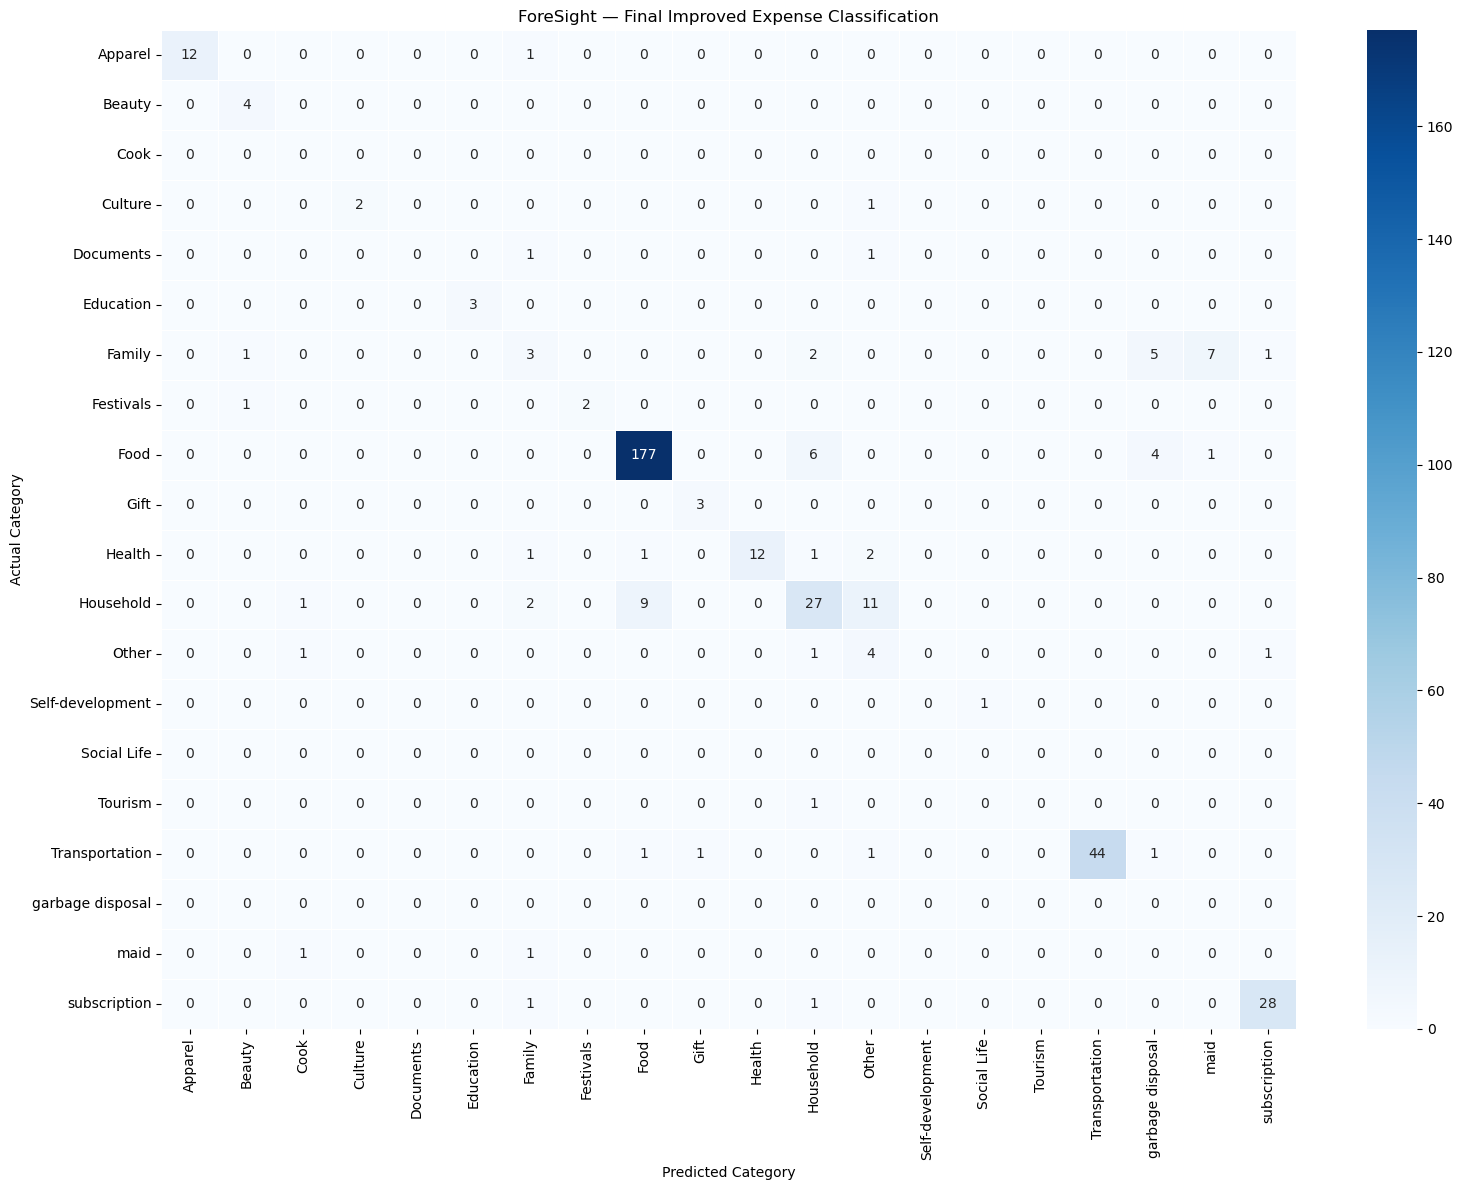

Confusion matrix generated successfully.


In [173]:
# ============================================================
# FINAL VALIDATION — STEP 1.3
# FINAL IMPROVED MODEL CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

all_labels = sorted(
    set(y_test_final.unique())
    | set(y_pred_final)
)

final_cm = confusion_matrix(
    y_test_final,
    y_pred_final,
    labels=all_labels
)

final_cm_df = pd.DataFrame(
    final_cm,
    index=all_labels,
    columns=all_labels
)

print("FINAL CONFUSION MATRIX")
display(final_cm_df)

plt.figure(figsize=(16, 12))

sns.heatmap(
    final_cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title(
    "ForeSight — Final Improved Expense Classification"
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

print("Confusion matrix generated successfully.")

In [174]:
# ============================================================
# FINAL VALIDATION — STEP 1.4
# PER-CATEGORY PERFORMANCE AUDIT
# ============================================================

from sklearn.metrics import classification_report

final_category_report = classification_report(
    y_test_supported_final,
    y_pred_supported_final,
    output_dict=True,
    zero_division=0
)

category_audit = pd.DataFrame([
    {
        "Category": category,
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1_Score": metrics["f1-score"],
        "Support": int(metrics["support"])
    }
    for category, metrics in final_category_report.items()
    if category not in [
        "accuracy",
        "macro avg",
        "weighted avg"
    ]
])

category_audit = category_audit.sort_values(
    ["F1_Score", "Support"],
    ascending=[True, False]
)

print("CATEGORY-WISE PERFORMANCE")
display(category_audit.round(3))

print("\nWeakest categories:")

display(
    category_audit.head(10).round(3)
)

print("\nCategories with zero F1:")
display(
    category_audit[
        category_audit["F1_Score"] == 0
    ]
)

print("\nCATEGORY AUDIT COMPLETED")

CATEGORY-WISE PERFORMANCE


,Category,Precision,Recall,F1_Score,Support
17,maid,0.000,0.000,0.000,2
12,Self-development,0.000,0.000,0.000,1
14,Tourism,0.000,0.000,0.000,1
2,Cook,0.000,0.000,0.000,0
13,Social Life,0.000,0.000,0.000,0
16,garbage disposal,0.000,0.000,0.000,0
5,Family,0.333,0.158,0.214,19
11,Other,0.211,0.571,0.308,7
10,Household,0.692,0.540,0.607,50
1,Beauty,0.667,1.000,0.800,4



Weakest categories:


,Category,Precision,Recall,F1_Score,Support
17,maid,0.000,0.000,0.000,2
12,Self-development,0.000,0.000,0.000,1
14,Tourism,0.000,0.000,0.000,1
2,Cook,0.000,0.000,0.000,0
13,Social Life,0.000,0.000,0.000,0
16,garbage disposal,0.000,0.000,0.000,0
5,Family,0.333,0.158,0.214,19
11,Other,0.211,0.571,0.308,7
10,Household,0.692,0.540,0.607,50
1,Beauty,0.667,1.000,0.800,4



Categories with zero F1:


,Category,Precision,Recall,F1_Score,Support
17,maid,0.0,0.0,0.0,2
12,Self-development,0.0,0.0,0.0,1
14,Tourism,0.0,0.0,0.0,1
2,Cook,0.0,0.0,0.0,0
13,Social Life,0.0,0.0,0.0,0
16,garbage disposal,0.0,0.0,0.0,0



CATEGORY AUDIT COMPLETED


In [175]:
# ============================================================
# FINAL VALIDATION — STEP 1.5
# EXTRACT ALL INCORRECT PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

error_analysis = test_df.copy()

error_analysis["Actual_Category"] = (
    y_test_final.to_numpy()
)

error_analysis["Predicted_Category"] = (
    np.asarray(y_pred_final)
)

error_analysis["Correct"] = (
    error_analysis["Actual_Category"]
    == error_analysis["Predicted_Category"]
)

incorrect_predictions = (
    error_analysis[
        ~error_analysis["Correct"]
    ].copy()
)

print("TOTAL TEST TRANSACTIONS:", len(error_analysis))
print("CORRECT:", error_analysis["Correct"].sum())
print("INCORRECT:", len(incorrect_predictions))

print("\nINCORRECT PREDICTIONS:")

display(
    incorrect_predictions[
        [
            "Date",
            "Note",
            "Amount",
            "Actual_Category",
            "Predicted_Category"
        ]
    ].sort_values("Actual_Category")
)

assert len(incorrect_predictions) == (
    len(y_test_final) - correct_all
)

print("\nERROR EXTRACTION VERIFIED")

TOTAL TEST TRANSACTIONS: 394
CORRECT: 321
INCORRECT: 73

INCORRECT PREDICTIONS:


,Date,Note,Amount,Actual_Category,Predicted_Category
1797,2018-06-27,Purse,450.0,Apparel,Family
1618,2018-03-23,Finding next Job,100.0,Culture,Other
1640,2018-04-01,Aadhar Address Change,50.0,Documents,Family
1763,2018-06-03,Aadhar PUC card delivery,50.0,Documents,Other
1719,2018-05-08,Bows,398.0,Family,Household
...,...,...,...,...,...
1887,2018-08-07,To and Fro Cab Fare Contribution,675.0,Transportation,Gift
1680,2018-04-23,No Note,500.0,maid,Cook
1865,2018-07-31,July salary,2000.0,maid,Family
1987,2018-12-04,No Note,199.0,subscription,Family



ERROR EXTRACTION VERIFIED


In [176]:
# ============================================================
# FINAL VALIDATION — STEP 1.6
# ERROR PATTERN ANALYSIS
# ============================================================

error_patterns = (
    incorrect_predictions
    .groupby(
        ["Actual_Category", "Predicted_Category"]
    )
    .size()
    .reset_index(name="Error_Count")
    .sort_values(
        "Error_Count",
        ascending=False
    )
)

print("MOST COMMON CLASSIFICATION ERRORS")

display(error_patterns)

print("\nERRORS BY ACTUAL CATEGORY")

actual_error_summary = (
    incorrect_predictions
    .groupby("Actual_Category")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Error_Count")
)

display(actual_error_summary)

print("\nERRORS BY PREDICTED CATEGORY")

predicted_error_summary = (
    incorrect_predictions
    .groupby("Predicted_Category")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="Error_Count")
)

display(predicted_error_summary)

MOST COMMON CLASSIFICATION ERRORS


,Actual_Category,Predicted_Category,Error_Count
20,Household,Other,11
19,Household,Food,9
7,Family,maid,7
10,Food,Household,6
6,Family,garbage disposal,5
11,Food,garbage disposal,4
18,Household,Family,2
16,Health,Other,2
5,Family,Household,2
0,Apparel,Family,1



ERRORS BY ACTUAL CATEGORY


,Actual_Category,Error_Count
0,Household,23
1,Family,16
2,Food,11
3,Health,5
4,Transportation,4
5,Other,3
6,subscription,2
7,maid,2
8,Documents,2
9,Apparel,1



ERRORS BY PREDICTED CATEGORY


,Predicted_Category,Error_Count
0,Other,16
1,Household,12
2,Food,11
3,garbage disposal,10
4,maid,8
5,Family,7
6,Cook,3
7,Beauty,2
8,subscription,2
9,Gift,1


In [177]:
# ============================================================
# FINAL VALIDATION — STEP 1.7
# TARGETED RARE CATEGORY INVESTIGATION
# ============================================================

weak_categories = [
    "Family",
    "Other",
    "Household",
    "maid",
    "Self-development",
    "Tourism",
    "Documents"
]

print("TARGETED CATEGORY ERROR REVIEW")

for category in weak_categories:

    actual_cases = error_analysis[
        error_analysis["Actual_Category"] == category
    ]

    mistakes = actual_cases[
        ~actual_cases["Correct"]
    ]

    print("\n" + "=" * 65)
    print("CATEGORY:", category)
    print("Total test examples:", len(actual_cases))
    print("Incorrect predictions:", len(mistakes))

    if len(mistakes) > 0:

        display(
            mistakes[
                [
                    "Date",
                    "Note",
                    "Amount",
                    "Actual_Category",
                    "Predicted_Category"
                ]
            ]
        )

print("\nTARGETED INVESTIGATION COMPLETED")

TARGETED CATEGORY ERROR REVIEW

CATEGORY: Family
Total test examples: 19
Incorrect predictions: 16


,Date,Note,Amount,Actual_Category,Predicted_Category
1608,2018-03-21,No Note,50.0,Family,garbage disposal
1644,2018-04-03,No Note,450.0,Family,maid
1650,2018-04-07,No Note,350.0,Family,maid
1658,2018-04-15,Body mist,525.0,Family,Household
1683,2018-04-26,No Note,1000.0,Family,maid
1687,2018-04-28,No Note,500.0,Family,maid
1699,2018-05-02,No Note,500.0,Family,maid
1709,2018-05-05,No Note,600.0,Family,maid
1714,2018-05-08,No Note,100.0,Family,garbage disposal
1719,2018-05-08,Bows,398.0,Family,Household



CATEGORY: Other
Total test examples: 7
Incorrect predictions: 3


,Date,Note,Amount,Actual_Category,Predicted_Category
1603,2018-03-20,No Note,17.0,Other,Cook
1704,2018-05-03,blanket sewing,10.0,Other,Household
1944,2018-09-13,HBR 2 Months subscription,83.0,Other,subscription



CATEGORY: Household
Total test examples: 50
Incorrect predictions: 23


,Date,Note,Amount,Actual_Category,Predicted_Category
1638,2018-04-01,Cockroach injection,270.0,Household,Other
1639,2018-04-01,Nandadip oil bottle,130.0,Household,Food
1657,2018-04-15,"Vessels for sugar, coffee and tea",799.0,Household,Food
1665,2018-04-16,Cockroach injection,270.0,Household,Other
1672,2018-04-19,flour mill,14.0,Household,Other
1737,2018-05-15,LG Washing Machine,21500.0,Household,Cook
1741,2018-05-19,flour mill,25.0,Household,Other
1749,2018-05-27,Soap + dahya pav kg,75.0,Household,Food
1754,2018-06-01,5 litres can Distilled water,100.0,Household,Food
1789,2018-06-26,Aqugurad water purifier,13050.0,Household,Family


... (5 outputs left out)

,Date,Note,Amount,Actual_Category,Predicted_Category
1793,2018-06-27,Planetarium,308.85,Tourism,Household



CATEGORY: Documents
Total test examples: 2
Incorrect predictions: 2


,Date,Note,Amount,Actual_Category,Predicted_Category
1640,2018-04-01,Aadhar Address Change,50.0,Documents,Family
1763,2018-06-03,Aadhar PUC card delivery,50.0,Documents,Other



TARGETED INVESTIGATION COMPLETED


In [178]:
# ============================================================
# FINAL VALIDATION — STEP 2.1
# CROSS-SPLIT DUPLICATE AUDIT
# ============================================================

audit_columns = [
    "Date",
    "Note",
    "Amount",
    "Mode",
    "Category"
]

train_audit = train_df[audit_columns].copy()
test_audit = test_df[audit_columns].copy()

for df in [train_audit, test_audit]:
    df["Note"] = (
        df["Note"].fillna("").astype(str).str.strip().str.lower()
    )

    df["Mode"] = (
        df["Mode"].fillna("").astype(str).str.strip().str.lower()
    )

train_signatures = set(
    map(tuple, train_audit.to_numpy())
)

test_signatures = set(
    map(tuple, test_audit.to_numpy())
)

cross_split_matches = (
    train_signatures & test_signatures
)

print("TRAIN ROWS:", len(train_audit))
print("TEST ROWS:", len(test_audit))

print(
    "Exact transaction matches across splits:",
    len(cross_split_matches)
)

assert len(train_signatures) >= 0
assert len(test_signatures) >= 0

print("\nCROSS-SPLIT DUPLICATE AUDIT COMPLETED")

TRAIN ROWS: 1602
TEST ROWS: 394
Exact transaction matches across splits: 0

CROSS-SPLIT DUPLICATE AUDIT COMPLETED


In [179]:
# ============================================================
# FINAL VALIDATION — STEP 2.2
# PREPROCESSING FIT AUDIT
# ============================================================

from sklearn.pipeline import Pipeline

print("FINAL MODEL:", final_classification_model)

assert isinstance(final_classification_model, Pipeline)

fitted_preprocessor = (
    final_classification_model.named_steps["preprocessor"]
)

fitted_classifier = (
    final_classification_model.named_steps["classifier"]
)

print("\nFITTED PREPROCESSOR COMPONENTS:")

for name, transformer, columns in (
    fitted_preprocessor.transformers_
):
    print(name, "->", columns)

print("\nCLASSIFIER:", type(fitted_classifier).__name__)

print(
    "Training samples recorded by classifier:",
    fitted_classifier.n_iter_
)

print("\nPREPROCESSING STRUCTURE INSPECTED")

FINAL MODEL: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('word',
                                                  TfidfVectorizer(max_features=10000,
                                                                  min_df=2,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  strip_accents='unicode',
                                                                  sublinear_tf=True),
                                                  'Note'),
                                                 ('char',
                                                  TfidfVectorizer(analyzer='char_wb',
                                                                  max_features=20000,
                                                                  min_df=2,
                           

In [180]:
# ============================================================
# FINAL VALIDATION — STEP 2.3
# TRAINING-ONLY FEATURE LEARNING AUDIT
# ============================================================

word_vectorizer = (
    fitted_preprocessor.named_transformers_["word"]
)

char_vectorizer = (
    fitted_preprocessor.named_transformers_["char"]
)

numeric_pipeline = (
    fitted_preprocessor.named_transformers_["numeric"]
)

scaler = numeric_pipeline.named_steps["scaler"]

print("WORD VOCABULARY SIZE:",
      len(word_vectorizer.vocabulary_))

print("CHARACTER VOCABULARY SIZE:",
      len(char_vectorizer.vocabulary_))

print("\nNUMERICAL SCALER MEANS:")
print(scaler.mean_)

print("\nNUMERICAL SCALER VARIANCES:")
print(scaler.var_)

print("\nTRAINING ROW COUNT:",
      len(X_train_final))

print("TEST ROW COUNT:",
      len(X_test_final))

assert len(word_vectorizer.vocabulary_) > 0
assert len(char_vectorizer.vocabulary_) > 0
assert np.isfinite(scaler.mean_).all()
assert np.isfinite(scaler.var_).all()

print("\nLEARNED FEATURE AUDIT COMPLETED")

WORD VOCABULARY SIZE: 863
CHARACTER VOCABULARY SIZE: 5694

NUMERICAL SCALER MEANS:
[498.10102996   3.05555556   5.95817728]

NUMERICAL SCALER VARIANCES:
[5.78748410e+06 4.25346789e+00 1.40525580e+01]

TRAINING ROW COUNT: 1602
TEST ROW COUNT: 394

LEARNED FEATURE AUDIT COMPLETED


In [181]:
# ============================================================
# STEP 3.1 — SAVED CLASSIFIER LOADING TEST
# ============================================================

import sklearn
import joblib
import json
from pathlib import Path

print("SCIKIT-LEARN VERSION:", sklearn.__version__)
print("JOBLIB VERSION:", joblib.__version__)

model_path = Path("../models/foresight_expense_classifier.joblib")

metadata_path = Path(
    "../models/foresight_expense_classifier_metadata.json"
)

assert model_path.exists(), "Model file not found"
assert metadata_path.exists(), "Metadata file not found"

with open(metadata_path, "r") as f:
    saved_metadata = json.load(f)

print("\nMODEL METADATA:")
print(json.dumps(saved_metadata, indent=4))

loaded_classifier = joblib.load(model_path)

print("\nMODEL LOADED SUCCESSFULLY!")
print("Model type:", type(loaded_classifier))
print("Pipeline steps:", loaded_classifier.named_steps.keys())

SCIKIT-LEARN VERSION: 1.6.1
JOBLIB VERSION: 1.4.2

MODEL METADATA:
{
    "model_name": "Linear SVM with Word and Character TF-IDF",
    "version": "1.0",
    "features": [
        "Note",
        "Amount",
        "Mode",
        "DayOfWeek",
        "Month"
    ],
    "training_transactions": 1602,
    "test_transactions": 394,
    "supported_test_transactions": 392,
    "unsupported_test_transactions": 2,
    "accuracy": 0.8188775510204082,
    "macro_f1": 0.5265680575377387,
    "weighted_f1": 0.8357035483262525,
    "categories": [
        "Apparel",
        "Beauty",
        "Cook",
        "Culture",
        "Education",
        "Family",
        "Festivals",
        "Food",
        "Gift",
        "Grooming",
        "Health",
        "Household",
        "Other",
        "Rent",
        "Self-development",
        "Social Life",
        "Tourism",
        "Transportation",
        "garbage disposal",
        "maid",
        "subscription",
        "water (jar /tanker)"
    ]
}


In [182]:
# ============================================================
# STEP 3.2 — SAVED MODEL PREDICTION
# ============================================================

import numpy as np
import pandas as pd

# Verify feature structure
print("Expected features:")
print(feature_columns)

print("\nTest feature columns:")
print(X_test_final.columns.tolist())

assert X_test_final.columns.tolist() == feature_columns

# Generate predictions using independently loaded model
y_pred_saved = loaded_classifier.predict(
    X_test_final
)

print("\nNotebook predictions:", len(y_pred_final))
print("Saved model predictions:", len(y_pred_saved))

print("\nFirst 10 notebook predictions:")
print(np.asarray(y_pred_final)[:10])

print("\nFirst 10 saved model predictions:")
print(y_pred_saved[:10])

print("\nSAVED MODEL PREDICTION COMPLETED")

Expected features:
['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month']

Test feature columns:
['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month']

Notebook predictions: 394
Saved model predictions: 394

First 10 notebook predictions:
['Food' 'Cook' 'Food' 'Food' 'Food' 'Food' 'garbage disposal' 'Household'
 'Food' 'Food']

First 10 saved model predictions:
['Food' 'Cook' 'Food' 'Food' 'Food' 'Food' 'garbage disposal' 'Household'
 'Food' 'Food']

SAVED MODEL PREDICTION COMPLETED


In [183]:
# ============================================================
# STEP 3.2 — PREDICTION CONSISTENCY AUDIT
# ============================================================

notebook_predictions = np.asarray(y_pred_final)
saved_predictions = np.asarray(y_pred_saved)

assert len(notebook_predictions) == len(saved_predictions)

matching_mask = (
    notebook_predictions == saved_predictions
)

matching_count = int(matching_mask.sum())
mismatch_count = int((~matching_mask).sum())

consistency_percentage = (
    matching_count / len(notebook_predictions)
) * 100

print("=" * 60)
print("SAVED MODEL CONSISTENCY REPORT")
print("=" * 60)

print("Total predictions:", len(notebook_predictions))
print("Matching predictions:", matching_count)
print("Mismatched predictions:", mismatch_count)

print(
    "Prediction consistency:",
    round(consistency_percentage, 2),
    "%"
)

if mismatch_count == 0:
    print("\nRESULT: EXACT PREDICTION CONSISTENCY")
else:
    print("\nRESULT: PREDICTION MISMATCH DETECTED")

SAVED MODEL CONSISTENCY REPORT
Total predictions: 394
Matching predictions: 394
Mismatched predictions: 0
Prediction consistency: 100.0 %

RESULT: EXACT PREDICTION CONSISTENCY


In [184]:
# ============================================================
# STEP 3.2 — MISMATCH INVESTIGATION
# ============================================================

mismatch_indices = np.where(~matching_mask)[0]

if len(mismatch_indices) > 0:

    mismatch_report = X_test_final.iloc[
        mismatch_indices
    ].copy()

    mismatch_report["Actual_Category"] = (
        y_test_final.iloc[mismatch_indices].to_numpy()
    )

    mismatch_report["Notebook_Prediction"] = (
        notebook_predictions[mismatch_indices]
    )

    mismatch_report["Saved_Model_Prediction"] = (
        saved_predictions[mismatch_indices]
    )

    print("PREDICTION MISMATCH DETAILS:")

    display(mismatch_report)

else:

    print("No prediction mismatches found.")

    print(
        "The saved model reproduces all notebook "
        "predictions exactly."
    )

No prediction mismatches found.
The saved model reproduces all notebook predictions exactly.


In [185]:
# ============================================================
# STEP 3.2 — SAVED METADATA CONSISTENCY AUDIT
# ============================================================

from sklearn.metrics import accuracy_score, f1_score

# Recalculate evaluation metrics from notebook predictions
current_accuracy = accuracy_score(
    y_test_supported_final,
    y_pred_supported_final
)

current_macro_f1 = f1_score(
    y_test_supported_final,
    y_pred_supported_final,
    average="macro",
    zero_division=0
)

current_weighted_f1 = f1_score(
    y_test_supported_final,
    y_pred_supported_final,
    average="weighted",
    zero_division=0
)

checks = {
    "Feature names": (
        saved_metadata["features"] == feature_columns
    ),
    "Training count": (
        saved_metadata["training_transactions"] == len(X_train_final)
    ),
    "Test count": (
        saved_metadata["test_transactions"] == len(X_test_final)
    ),
    "Category labels": (
        saved_metadata["categories"]
        == sorted(y_train_final.unique().tolist())
    ),
    "Accuracy": np.isclose(
        saved_metadata["accuracy"], current_accuracy
    ),
    "Macro F1": np.isclose(
        saved_metadata["macro_f1"], current_macro_f1
    ),
    "Weighted F1": np.isclose(
        saved_metadata["weighted_f1"], current_weighted_f1
    )
}

metadata_audit = pd.DataFrame([
    {"Check": name, "Status": "PASS" if passed else "FAIL"}
    for name, passed in checks.items()
])

display(metadata_audit)

print("\nPASSED:", sum(checks.values()))
print("FAILED:", len(checks) - sum(checks.values()))

if all(checks.values()):
    print("\nMETADATA CONSISTENCY: PASSED")
else:
    print("\nMETADATA CONSISTENCY: INVESTIGATION REQUIRED")

,Check,Status
0,Feature names,PASS
1,Training count,PASS
2,Test count,PASS
3,Category labels,PASS
4,Accuracy,PASS
5,Macro F1,PASS
6,Weighted F1,PASS



PASSED: 7
FAILED: 0

METADATA CONSISTENCY: PASSED


In [186]:
# ============================================================
# STEP 3.3 — PREPARE NEW TRANSACTION INPUTS
# ============================================================

import pandas as pd
import numpy as np

# Use an existing payment mode from training data
known_mode = (
    train_df["Mode"]
    .dropna()
    .astype(str)
    .iloc[0]
)

# Illustrative transactions — inference only
new_transaction_data = pd.DataFrame([
    {
        "Note": "Monthly electricity bill payment",
        "Amount": 1850.0,
        "Mode": known_mode,
        "Date": "2026-11-05"
    },
    {
        "Note": "Grocery store vegetables and milk",
        "Amount": 750.0,
        "Mode": known_mode,
        "Date": "2026-11-07"
    },
    {
        "Note": "Metro card recharge",
        "Amount": 500.0,
        "Mode": known_mode,
        "Date": "2026-11-09"
    },
    {
        "Note": "Doctor consultation fee",
        "Amount": 800.0,
        "Mode": known_mode,
        "Date": "2026-11-11"
    },
    {
        "Note": "Movie tickets with friends",
        "Amount": 600.0,
        "Mode": known_mode,
        "Date": "2026-11-14"
    }
])

# Derive temporal features
new_transaction_data["Date"] = pd.to_datetime(
    new_transaction_data["Date"]
)

new_transaction_data["DayOfWeek"] = (
    new_transaction_data["Date"].dt.dayofweek
)

new_transaction_data["Month"] = (
    new_transaction_data["Date"].dt.month
)

# Prepare model inputs in the original feature order
X_new_transactions = new_transaction_data[
    feature_columns
].copy()

print("NEW TRANSACTIONS:")
display(new_transaction_data)

print("\nMODEL INPUT FEATURES:")
display(X_new_transactions)

assert list(X_new_transactions.columns) == feature_columns

print("\nNEW TRANSACTION INPUTS PREPARED")

NEW TRANSACTIONS:


,Note,Amount,Mode,Date,DayOfWeek,Month
0,Monthly electricity bill payment,1850.0,Cash,2026-11-05,3,11
1,Grocery store vegetables and milk,750.0,Cash,2026-11-07,5,11
2,Metro card recharge,500.0,Cash,2026-11-09,0,11
3,Doctor consultation fee,800.0,Cash,2026-11-11,2,11
4,Movie tickets with friends,600.0,Cash,2026-11-14,5,11



MODEL INPUT FEATURES:


,Note,Amount,Mode,DayOfWeek,Month
0,Monthly electricity bill payment,1850.0,Cash,3,11
1,Grocery store vegetables and milk,750.0,Cash,5,11
2,Metro card recharge,500.0,Cash,0,11
3,Doctor consultation fee,800.0,Cash,2,11
4,Movie tickets with friends,600.0,Cash,5,11



NEW TRANSACTION INPUTS PREPARED


In [187]:
# ============================================================
# STEP 3.3 — NEW TRANSACTION PREDICTION
# ============================================================

new_predictions = loaded_classifier.predict(
    X_new_transactions
)

new_transaction_results = new_transaction_data.copy()

new_transaction_results["Predicted_Category"] = (
    new_predictions
)

print("NEW TRANSACTION PREDICTIONS:")
display(
    new_transaction_results[
        [
            "Note",
            "Amount",
            "Predicted_Category"
        ]
    ]
)

print("\nTOTAL TRANSACTIONS:", len(new_predictions))

print("\nPREDICTED CATEGORIES:")
print(new_predictions)

print("\nNEW TRANSACTION INFERENCE COMPLETED")

NEW TRANSACTION PREDICTIONS:


,Note,Amount,Predicted_Category
0,Monthly electricity bill payment,1850.0,Household
1,Grocery store vegetables and milk,750.0,Food
2,Metro card recharge,500.0,Other
3,Doctor consultation fee,800.0,Health
4,Movie tickets with friends,600.0,Culture



TOTAL TRANSACTIONS: 5

PREDICTED CATEGORIES:
['Household' 'Food' 'Other' 'Health' 'Culture']

NEW TRANSACTION INFERENCE COMPLETED


In [188]:
# ============================================================
# STEP 3.3 — INFERENCE OUTPUT VALIDATION
# ============================================================

model_classes = set(
    loaded_classifier.named_steps[
        "classifier"
    ].classes_
)

# Check prediction labels
valid_predictions = all(
    prediction in model_classes
    for prediction in new_predictions
)

# Check prediction count
correct_count = (
    len(new_predictions) == len(X_new_transactions)
)

# Check missing predictions
no_missing_predictions = pd.notna(
    new_predictions
).all()

# Run inference again to test reproducibility
repeat_predictions = loaded_classifier.predict(
    X_new_transactions
)

repeatable_predictions = np.array_equal(
    new_predictions,
    repeat_predictions
)

inference_checks = {
    "Correct prediction count": correct_count,
    "Valid model category labels": valid_predictions,
    "No missing predictions": no_missing_predictions,
    "Repeatable predictions": repeatable_predictions
}

inference_audit = pd.DataFrame([
    {
        "Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in inference_checks.items()
])

display(inference_audit)

print("\nPASSED:", sum(inference_checks.values()))
print("FAILED:", len(inference_checks) - sum(inference_checks.values()))

if all(inference_checks.values()):
    print("\nNEW TRANSACTION INFERENCE: PASSED")
else:
    print("\nNEW TRANSACTION INFERENCE: INVESTIGATION REQUIRED")

,Check,Status
0,Correct prediction count,PASS
1,Valid model category labels,PASS
2,No missing predictions,PASS
3,Repeatable predictions,PASS



PASSED: 4
FAILED: 0

NEW TRANSACTION INFERENCE: PASSED


In [189]:
# ============================================================
# STEP 3.3 — INFERENCE OUTPUT VALIDATION
# ============================================================

model_classes = set(
    loaded_classifier.named_steps[
        "classifier"
    ].classes_
)

# Check prediction labels
valid_predictions = all(
    prediction in model_classes
    for prediction in new_predictions
)

# Check prediction count
correct_count = (
    len(new_predictions) == len(X_new_transactions)
)

# Check missing predictions
no_missing_predictions = pd.notna(
    new_predictions
).all()

# Run inference again to test reproducibility
repeat_predictions = loaded_classifier.predict(
    X_new_transactions
)

repeatable_predictions = np.array_equal(
    new_predictions,
    repeat_predictions
)

inference_checks = {
    "Correct prediction count": correct_count,
    "Valid model category labels": valid_predictions,
    "No missing predictions": no_missing_predictions,
    "Repeatable predictions": repeatable_predictions
}

inference_audit = pd.DataFrame([
    {
        "Check": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in inference_checks.items()
])

display(inference_audit)

print("\nPASSED:", sum(inference_checks.values()))
print("FAILED:", len(inference_checks) - sum(inference_checks.values()))

if all(inference_checks.values()):
    print("\nNEW TRANSACTION INFERENCE: PASSED")
else:
    print("\nNEW TRANSACTION INFERENCE: INVESTIGATION REQUIRED")

,Check,Status
0,Correct prediction count,PASS
1,Valid model category labels,PASS
2,No missing predictions,PASS
3,Repeatable predictions,PASS



PASSED: 4
FAILED: 0

NEW TRANSACTION INFERENCE: PASSED


In [190]:
# ============================================================
# STEP 3.3 — DECISION SCORE DIAGNOSTIC
# ============================================================

decision_scores = loaded_classifier.decision_function(
    X_new_transactions
)

# Get the two highest class scores per transaction
sorted_scores = np.sort(
    decision_scores,
    axis=1
)

top_scores = sorted_scores[:, -1]

if decision_scores.shape[1] >= 2:
    second_scores = sorted_scores[:, -2]
    score_margins = top_scores - second_scores
else:
    second_scores = np.full(len(top_scores), np.nan)
    score_margins = np.full(len(top_scores), np.nan)

decision_audit = pd.DataFrame({
    "Note": new_transaction_data["Note"],
    "Predicted_Category": new_predictions,
    "Top_Decision_Score": top_scores,
    "Second_Decision_Score": second_scores,
    "Score_Margin": score_margins
})

print("LINEAR SVM DECISION SCORE ANALYSIS")

display(decision_audit.round(4))

print(
    "\nNOTE: These scores are diagnostic only, "
    "not prediction probabilities."
)

LINEAR SVM DECISION SCORE ANALYSIS


,Note,Predicted_Category,Top_Decision_Score,Second_Decision_Score,Score_Margin
0,Monthly electricity bill payment,Household,0.4729,-0.6369,1.1098
1,Grocery store vegetables and milk,Food,0.7618,-0.5477,1.3095
2,Metro card recharge,Other,0.1276,-0.7754,0.9030
3,Doctor consultation fee,Health,0.6732,-0.3029,0.9761
4,Movie tickets with friends,Culture,0.1516,-0.8287,0.9803



NOTE: These scores are diagnostic only, not prediction probabilities.


In [191]:

# ============================================================
# FORESIGHT — CLASSIFICATION FINAL VALIDATION
# STEP 4: EMPTY, INVALID AND UNSEEN INPUT TESTING
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE MODEL COMPONENTS
# ------------------------------------------------------------

assert "loaded_classifier" in globals(), "Load saved model first"

preprocessor = loaded_classifier.named_steps["preprocessor"]

word_vectorizer = preprocessor.named_transformers_["word"]
char_vectorizer = preprocessor.named_transformers_["char"]
mode_encoder = preprocessor.named_transformers_["mode"]

known_modes = set(
    str(x) for x in mode_encoder.categories_[0]
)

known_classes = set(
    loaded_classifier.named_steps["classifier"].classes_
)

print("MODEL READY FOR EDGE-CASE TESTING")
print("Known categories:", len(known_classes))
print("Known payment modes:", known_modes)


# ------------------------------------------------------------
# 2. CREATE TEST INPUTS
# ------------------------------------------------------------

base_transaction = {
    "Note": "Monthly grocery purchase",
    "Amount": 850.0,
    "Mode": known_mode,
    "DayOfWeek": 2,
    "Month": 11
}

def make_test_input(**changes):
    row = base_transaction.copy()
    row.update(changes)
    return pd.DataFrame([row], columns=feature_columns)


test_cases = {
    "Valid transaction": make_test_input(),

    "Empty description": make_test_input(
        Note=""
    ),

    "Missing description": make_test_input(
        Note=np.nan
    ),

    "Completely unseen description": make_test_input(
        Note="qzxvplm blorftastic unknownword"
    ),

    "Unseen payment mode": make_test_input(
        Mode="UNKNOWN_PAYMENT_MODE_999"
    ),

    "Missing amount": make_test_input(
        Amount=np.nan
    ),

    "Invalid amount text": make_test_input(
        Amount="not-a-number"
    ),

    "Negative amount": make_test_input(
        Amount=-500.0
    ),

    "Infinite amount": make_test_input(
        Amount=np.inf
    ),

    "Invalid day of week": make_test_input(
        DayOfWeek=7
    ),

    "Invalid month": make_test_input(
        Month=13
    ),

    "Missing payment mode": make_test_input(
        Mode=np.nan
    ),

    "Missing required column": make_test_input().drop(
        columns=["Month"]
    )
}


# ------------------------------------------------------------
# 3. TEST RAW SAVED MODEL BEHAVIOUR
# ------------------------------------------------------------

raw_results = []

for case_name, case_df in test_cases.items():

    try:
        prediction = loaded_classifier.predict(case_df)

        raw_results.append({
            "Test": case_name,
            "Model Behaviour": "ACCEPTED",
            "Prediction": str(prediction[0]),
            "Error": None
        })

    except Exception as error:

        raw_results.append({
            "Test": case_name,
            "Model Behaviour": "REJECTED",
            "Prediction": None,
            "Error": str(error)[:180]
        })

raw_audit = pd.DataFrame(raw_results)

print("\n" + "=" * 65)
print("RAW SAVED MODEL EDGE-CASE RESULTS")
print("=" * 65)

display(raw_audit)


# ------------------------------------------------------------
# 4. DEFINE A TEMPORARY APPLICATION INPUT VALIDATOR
# ------------------------------------------------------------

def validate_transaction_input(df):

    errors = []
    warnings = []

    if not isinstance(df, pd.DataFrame):
        return ["Input must be a pandas DataFrame."], []

    missing_columns = [
        col for col in feature_columns
        if col not in df.columns
    ]

    extra_columns = [
        col for col in df.columns
        if col not in feature_columns
    ]

    if missing_columns:
        errors.append(
            f"Missing columns: {missing_columns}"
        )

    if extra_columns:
        errors.append(
            f"Unexpected columns: {extra_columns}"
        )

    if missing_columns or extra_columns:
        return errors, warnings

    if len(df) != 1:
        errors.append("Exactly one transaction is expected.")
        return errors, warnings

    row = df.iloc[0]

    # Description validation
    note = row["Note"]

    if pd.isna(note):
        errors.append("Transaction description is missing.")

    elif not isinstance(note, str):
        errors.append("Description must be text.")

    elif not note.strip():
        warnings.append(
            "Empty description: manual review recommended."
        )

    # Amount validation
    amount = row["Amount"]

    if (
        not isinstance(amount, (int, float, np.integer, np.floating))
        or isinstance(amount, (bool, np.bool_))
    ):
        errors.append("Amount must be numeric.")

    elif not np.isfinite(amount):
        errors.append("Amount must be finite.")

    elif amount < 0:
        errors.append("Amount cannot be negative.")

    # Payment mode validation
    mode = row["Mode"]

    if pd.isna(mode) or not isinstance(mode, str) or not mode.strip():
        errors.append("Payment mode is missing or invalid.")

    elif mode not in known_modes:
        warnings.append(
            "Unseen payment mode: manual review recommended."
        )

    # Day of week validation
    day = row["DayOfWeek"]

    if (
        not isinstance(day, (int, float, np.integer, np.floating))
        or not np.isfinite(day)
        or int(day) != day
        or not 0 <= day <= 6
    ):
        errors.append("DayOfWeek must be an integer from 0 to 6.")

    # Month validation
    month = row["Month"]

    if (
        not isinstance(month, (int, float, np.integer, np.floating))
        or not np.isfinite(month)
        or int(month) != month
        or not 1 <= month <= 12
    ):
        errors.append("Month must be an integer from 1 to 12.")

    # Check whether description contains learned text features
    if isinstance(note, str) and note.strip():

        word_count = word_vectorizer.transform([note]).nnz
        char_count = char_vectorizer.transform([note]).nnz

        if word_count == 0 and char_count == 0:
            warnings.append(
                "No known text features: manual review recommended."
            )

    return errors, warnings


# ------------------------------------------------------------
# 5. RUN APPLICATION-LEVEL VALIDATION
# ------------------------------------------------------------

guard_results = []

for case_name, case_df in test_cases.items():

    errors, warnings = validate_transaction_input(case_df)

    prediction = None

    if not errors:

        try:
            prediction = loaded_classifier.predict(
                case_df[feature_columns]
            )[0]

        except Exception as error:
            errors.append(
                f"Model inference failed: {str(error)[:150]}"
            )

    guard_results.append({
        "Test": case_name,
        "Input Status": "ACCEPTED" if not errors else "REJECTED",
        "Predicted Category": prediction,
        "Manual Review": "YES" if warnings else "NO",
        "Errors": " | ".join(errors) if errors else "None",
        "Warnings": " | ".join(warnings) if warnings else "None"
    })

guard_audit = pd.DataFrame(guard_results)

print("\n" + "=" * 65)
print("FORESIGHT APPLICATION INPUT VALIDATION")
print("=" * 65)

display(guard_audit)


# ------------------------------------------------------------
# 6. VERIFY EXPECTED INPUT HANDLING
# ------------------------------------------------------------

expected_status = {
    "Valid transaction": "ACCEPTED",
    "Empty description": "ACCEPTED",
    "Missing description": "REJECTED",
    "Completely unseen description": "ACCEPTED",
    "Unseen payment mode": "ACCEPTED",
    "Missing amount": "REJECTED",
    "Invalid amount text": "REJECTED",
    "Negative amount": "REJECTED",
    "Infinite amount": "REJECTED",
    "Invalid day of week": "REJECTED",
    "Invalid month": "REJECTED",
    "Missing payment mode": "REJECTED",
    "Missing required column": "REJECTED"
}

actual_status = dict(
    zip(
        guard_audit["Test"],
        guard_audit["Input Status"]
    )
)

validation_checks = {
    name: actual_status.get(name) == expected
    for name, expected in expected_status.items()
}

validation_summary = pd.DataFrame([
    {
        "Test": name,
        "Expected": expected_status[name],
        "Actual": actual_status.get(name),
        "Status": "PASS" if validation_checks[name] else "FAIL"
    }
    for name in expected_status
])

print("\n" + "=" * 65)
print("FINAL EDGE-CASE VALIDATION SUMMARY")
print("=" * 65)

display(validation_summary)

passed = sum(validation_checks.values())
failed = len(validation_checks) - passed

print("\nPASSED:", passed)
print("FAILED:", failed)

if failed == 0:
    print("\nINPUT VALIDATION TESTS: ALL PASSED")
else:
    print("\nINPUT VALIDATION TESTS: INVESTIGATION REQUIRED")

print("\nIMPORTANT:")
print("This is a temporary validation harness.")
print("It does not modify or retrain the saved classifier.")
print("Manual-review warnings are not calibrated confidence scores.")


MODEL READY FOR EDGE-CASE TESTING
Known categories: 22
Known payment modes: {'Debit Card', 'Saving Bank account 1', 'Cash', 'Saving Bank account 2', 'Credit Card'}

RAW SAVED MODEL EDGE-CASE RESULTS


,Test,Model Behaviour,Prediction,Error
0,Valid transaction,ACCEPTED,Food,None
1,Empty description,ACCEPTED,Food,None
2,Missing description,REJECTED,None,'float' object has no attribute 'lower'
3,Completely unseen description,ACCEPTED,Household,None
4,Unseen payment mode,ACCEPTED,Food,None
5,Missing amount,ACCEPTED,Food,None
6,Invalid amount text,REJECTED,None,Cannot use median strategy with non-numeric da...
7,Negative amount,ACCEPTED,Food,None
8,Infinite amount,REJECTED,None,Input X contains infinity or a value too large...
9,Invalid day of week,ACCEPTED,Food,None



FORESIGHT APPLICATION INPUT VALIDATION


,Test,Input Status,Predicted Category,Manual Review,Errors,Warnings
0,Valid transaction,ACCEPTED,Food,NO,None,None
1,Empty description,ACCEPTED,Food,YES,None,Empty description: manual review recommended.
2,Missing description,REJECTED,None,NO,Transaction description is missing.,None
3,Completely unseen description,ACCEPTED,Household,NO,None,None
4,Unseen payment mode,ACCEPTED,Food,YES,None,Unseen payment mode: manual review recommended.
5,Missing amount,REJECTED,None,NO,Amount must be finite.,None
6,Invalid amount text,REJECTED,None,NO,Amount must be numeric.,None
7,Negative amount,REJECTED,None,NO,Amount cannot be negative.,None
8,Infinite amount,REJECTED,None,NO,Amount must be finite.,None
9,Invalid day of week,REJECTED,None,NO,DayOfWeek must be an integer from 0 to 6.,None



FINAL EDGE-CASE VALIDATION SUMMARY


,Test,Expected,Actual,Status
0,Valid transaction,ACCEPTED,ACCEPTED,PASS
1,Empty description,ACCEPTED,ACCEPTED,PASS
2,Missing description,REJECTED,REJECTED,PASS
3,Completely unseen description,ACCEPTED,ACCEPTED,PASS
4,Unseen payment mode,ACCEPTED,ACCEPTED,PASS
5,Missing amount,REJECTED,REJECTED,PASS
6,Invalid amount text,REJECTED,REJECTED,PASS
7,Negative amount,REJECTED,REJECTED,PASS
8,Infinite amount,REJECTED,REJECTED,PASS
9,Invalid day of week,REJECTED,REJECTED,PASS



PASSED: 13
FAILED: 0

INPUT VALIDATION TESTS: ALL PASSED

IMPORTANT:
This is a temporary validation harness.
It does not modify or retrain the saved classifier.
Manual-review warnings are not calibrated confidence scores.


In [192]:

# ============================================================
# FORESIGHT — STEP 5.1
# MANUAL REVIEW AND SAFE INFERENCE MECHANISM
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE MODEL COMPONENTS
# ------------------------------------------------------------

model = loaded_classifier

preprocessor = model.named_steps["preprocessor"]

word_vectorizer = (
    preprocessor.named_transformers_["word"]
)

mode_encoder = (
    preprocessor.named_transformers_["mode"]
)

known_modes = set(
    str(x) for x in mode_encoder.categories_[0]
)

known_classes = set(
    model.named_steps["classifier"].classes_
)


# ------------------------------------------------------------
# 2. CREATE SAFE INFERENCE FUNCTION
# ------------------------------------------------------------

def foresight_predict_with_review(transaction):

    result = {
        "Status": "REJECTED",
        "Predicted_Category": None,
        "Manual_Review": "NO",
        "Review_Reasons": [],
        "Top_Decision_Score": None,
        "Decision_Score_Margin": None,
        "Score_Interpretation": "Not calibrated"
    }

    # Check input type
    if not isinstance(transaction, pd.DataFrame):
        result["Review_Reasons"].append(
            "Input must be a pandas DataFrame."
        )
        return result

    # Check columns
    missing = [
        c for c in feature_columns
        if c not in transaction.columns
    ]

    extra = [
        c for c in transaction.columns
        if c not in feature_columns
    ]

    if missing or extra:
        result["Review_Reasons"].append(
            f"Missing columns: {missing}; Extra columns: {extra}"
        )
        return result

    if len(transaction) != 1:
        result["Review_Reasons"].append(
            "Exactly one transaction is required."
        )
        return result

    row = transaction[feature_columns].copy()

    # --------------------------------------------------------
    # DESCRIPTION VALIDATION
    # --------------------------------------------------------

    note = row["Note"].iloc[0]

    if not isinstance(note, str):
        result["Review_Reasons"].append(
            "Description is missing or is not text."
        )
        return result

    if not note.strip():
        result["Review_Reasons"].append(
            "Empty description."
        )

    else:
        known_word_features = (
            word_vectorizer.transform([note]).nnz
        )

        if known_word_features == 0:
            result["Review_Reasons"].append(
                "No known word vocabulary features."
            )

    # --------------------------------------------------------
    # AMOUNT VALIDATION
    # --------------------------------------------------------

    amount = row["Amount"].iloc[0]

    if (
        not isinstance(
            amount,
            (int, float, np.integer, np.floating)
        )
        or isinstance(amount, (bool, np.bool_))
    ):
        result["Review_Reasons"].append(
            "Amount must be numeric."
        )
        return result

    if not np.isfinite(amount):
        result["Review_Reasons"].append(
            "Amount must be finite."
        )
        return result

    if amount < 0:
        result["Review_Reasons"].append(
            "Negative spending amount."
        )
        return result

    # --------------------------------------------------------
    # PAYMENT MODE VALIDATION
    # --------------------------------------------------------

    mode = row["Mode"].iloc[0]

    if not isinstance(mode, str) or not mode.strip():
        result["Review_Reasons"].append(
            "Missing or invalid payment mode."
        )
        return result

    if mode not in known_modes:
        result["Review_Reasons"].append(
            "Unseen payment mode."
        )

    # --------------------------------------------------------
    # TEMPORAL FEATURE VALIDATION
    # --------------------------------------------------------

    day = row["DayOfWeek"].iloc[0]
    month = row["Month"].iloc[0]

    if (
        not isinstance(day, (int, float, np.integer, np.floating))
        or isinstance(day, (bool, np.bool_))
        or not np.isfinite(day)
        or int(day) != day
        or not 0 <= day <= 6
    ):
        result["Review_Reasons"].append(
            "Invalid DayOfWeek."
        )
        return result

    if (
        not isinstance(month, (int, float, np.integer, np.floating))
        or isinstance(month, (bool, np.bool_))
        or not np.isfinite(month)
        or int(month) != month
        or not 1 <= month <= 12
    ):
        result["Review_Reasons"].append(
            "Invalid Month."
        )
        return result

    # --------------------------------------------------------
    # 3. RUN SAVED MODEL INFERENCE
    # --------------------------------------------------------

    try:

        prediction = model.predict(row)[0]

        scores = model.decision_function(row)

        sorted_scores = np.sort(
            np.asarray(scores).reshape(-1)
        )

        top_score = float(sorted_scores[-1])

        margin = (
            float(sorted_scores[-1] - sorted_scores[-2])
            if len(sorted_scores) >= 2
            else None
        )

        if prediction not in known_classes:
            result["Review_Reasons"].append(
                "Prediction is outside known model categories."
            )
            return result

        result["Status"] = "ACCEPTED"
        result["Predicted_Category"] = str(prediction)
        result["Top_Decision_Score"] = top_score
        result["Decision_Score_Margin"] = margin

        if result["Review_Reasons"]:
            result["Manual_Review"] = "YES"

    except Exception as error:

        result["Status"] = "ERROR"
        result["Review_Reasons"].append(
            f"Inference error: {str(error)[:150]}"
        )

    return result


# ------------------------------------------------------------
# 4. TEST MANUAL REVIEW ON ALL EXISTING EDGE CASES
# ------------------------------------------------------------

review_results = []

for case_name, case_df in test_cases.items():

    output = foresight_predict_with_review(
        case_df
    )

    review_results.append({
        "Test": case_name,
        "Status": output["Status"],
        "Predicted_Category": output["Predicted_Category"],
        "Manual_Review": output["Manual_Review"],
        "Review_Reasons": " | ".join(
            output["Review_Reasons"]
        ) or "None",
        "Decision_Score_Margin": output[
            "Decision_Score_Margin"
        ]
    })


review_audit = pd.DataFrame(review_results)

print("=" * 70)
print("FORESIGHT MANUAL REVIEW AUDIT")
print("=" * 70)

display(review_audit)


# ------------------------------------------------------------
# 5. REVIEW SUMMARY
# ------------------------------------------------------------

accepted_count = (
    review_audit["Status"] == "ACCEPTED"
).sum()

rejected_count = (
    review_audit["Status"] == "REJECTED"
).sum()

review_count = (
    review_audit["Manual_Review"] == "YES"
).sum()

print("\nTOTAL TEST CASES:", len(review_audit))
print("ACCEPTED:", accepted_count)
print("REJECTED:", rejected_count)
print("MANUAL REVIEW REQUIRED:", review_count)

print("\nMANUAL REVIEW CASES:")

display(
    review_audit[
        review_audit["Manual_Review"] == "YES"
    ]
)

# ------------------------------------------------------------
# 6. VERIFY CORE REVIEW REQUIREMENTS
# ------------------------------------------------------------

required_review_cases = [
    "Empty description",
    "Completely unseen description",
    "Unseen payment mode"
]

review_lookup = dict(
    zip(
        review_audit["Test"],
        review_audit["Manual_Review"]
    )
)

review_checks = {
    case: review_lookup.get(case) == "YES"
    for case in required_review_cases
}

review_summary = pd.DataFrame([
    {
        "Requirement": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in review_checks.items()
])

print("\nCORE MANUAL REVIEW CHECKS:")
display(review_summary)

print(
    "\nPASSED:",
    sum(review_checks.values()),
    "/",
    len(review_checks)
)

if all(review_checks.values()):
    print("\nMANUAL REVIEW ROUTING: PASSED")
else:
    print("\nMANUAL REVIEW ROUTING: INVESTIGATION REQUIRED")


print("\nIMPORTANT:")
print("Decision scores are not calibrated probabilities.")
print("No automatic confidence threshold has been selected.")
print("This is a validation prototype, not final production code.")
print("The original saved classifier remains unchanged.")


FORESIGHT MANUAL REVIEW AUDIT


,Test,Status,Predicted_Category,Manual_Review,Review_Reasons,Decision_Score_Margin
0,Valid transaction,ACCEPTED,Food,NO,None,0.772725
1,Empty description,ACCEPTED,Food,YES,Empty description.,0.052198
2,Missing description,REJECTED,None,NO,Description is missing or is not text.,NaN
3,Completely unseen description,ACCEPTED,Household,YES,No known word vocabulary features.,0.496393
4,Unseen payment mode,ACCEPTED,Food,YES,Unseen payment mode.,0.388004
5,Missing amount,REJECTED,None,NO,Amount must be finite.,NaN
6,Invalid amount text,REJECTED,None,NO,Amount must be numeric.,NaN
7,Negative amount,REJECTED,None,NO,Negative spending amount.,NaN
8,Infinite amount,REJECTED,None,NO,Amount must be finite.,NaN
9,Invalid day of week,REJECTED,None,NO,Invalid DayOfWeek.,NaN



TOTAL TEST CASES: 13
ACCEPTED: 4
REJECTED: 9
MANUAL REVIEW REQUIRED: 3

MANUAL REVIEW CASES:


,Test,Status,Predicted_Category,Manual_Review,Review_Reasons,Decision_Score_Margin
1,Empty description,ACCEPTED,Food,YES,Empty description.,0.052198
3,Completely unseen description,ACCEPTED,Household,YES,No known word vocabulary features.,0.496393
4,Unseen payment mode,ACCEPTED,Food,YES,Unseen payment mode.,0.388004



CORE MANUAL REVIEW CHECKS:


,Requirement,Status
0,Empty description,PASS
1,Completely unseen description,PASS
2,Unseen payment mode,PASS



PASSED: 3 / 3

MANUAL REVIEW ROUTING: PASSED

IMPORTANT:
Decision scores are not calibrated probabilities.
No automatic confidence threshold has been selected.
This is a validation prototype, not final production code.
The original saved classifier remains unchanged.


In [193]:

# ============================================================
# FORESIGHT — STEP 5.2
# COMPLETE MANUAL REVIEW MECHANISM AUDIT
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. PREPARE ADDITIONAL INPUT CASES
# ------------------------------------------------------------

wrapper_test_cases = {
    "Valid transaction": make_test_input(),

    "Empty description": make_test_input(Note=""),

    "Whitespace description": make_test_input(Note="   "),

    "Missing description": make_test_input(Note=np.nan),

    "Unseen description": make_test_input(
        Note="qzxvplm blorftastic unknownword"
    ),

    "Unseen payment mode": make_test_input(
        Mode="UNKNOWN_PAYMENT_MODE_999"
    ),

    "Missing amount": make_test_input(Amount=np.nan),

    "Negative amount": make_test_input(Amount=-500),

    "Infinite amount": make_test_input(Amount=np.inf),

    "Invalid amount text": make_test_input(
        Amount="not-a-number"
    ),

    "Invalid day": make_test_input(DayOfWeek=7),

    "Invalid month": make_test_input(Month=13),

    "Missing payment mode": make_test_input(Mode=np.nan),

    "Missing column": make_test_input().drop(
        columns=["Month"]
    ),

    "Extra column": make_test_input().assign(
        Extra_Feature="unexpected"
    ),

    "Multiple transactions": pd.concat(
        [make_test_input(), make_test_input()],
        ignore_index=True
    ),

    "Non-DataFrame input": "invalid transaction"
}


# ------------------------------------------------------------
# 2. RUN THE ACTUAL INFERENCE WRAPPER
# ------------------------------------------------------------

wrapper_results = []

for test_name, test_input in wrapper_test_cases.items():

    try:

        output = foresight_predict_with_review(
            test_input
        )

        wrapper_results.append({
            "Test": test_name,
            "Status": output["Status"],
            "Prediction": output["Predicted_Category"],
            "Manual_Review": output["Manual_Review"],
            "Reasons": " | ".join(
                output["Review_Reasons"]
            ) or "None",
            "Decision_Margin": output[
                "Decision_Score_Margin"
            ]
        })

    except Exception as error:

        wrapper_results.append({
            "Test": test_name,
            "Status": "UNEXPECTED_ERROR",
            "Prediction": None,
            "Manual_Review": "UNKNOWN",
            "Reasons": str(error)[:200],
            "Decision_Margin": None
        })


wrapper_results_df = pd.DataFrame(wrapper_results)

print("=" * 75)
print("FORESIGHT — COMPLETE MANUAL REVIEW AUDIT")
print("=" * 75)

display(wrapper_results_df)


# ------------------------------------------------------------
# 3. VERIFY EXPECTED BEHAVIOUR
# ------------------------------------------------------------

expected_behaviour = {

    "Valid transaction": ("ACCEPTED", "NO"),

    "Empty description": ("ACCEPTED", "YES"),

    "Whitespace description": ("ACCEPTED", "YES"),

    "Missing description": ("REJECTED", "NO"),

    "Unseen description": ("ACCEPTED", "YES"),

    "Unseen payment mode": ("ACCEPTED", "YES"),

    "Missing amount": ("REJECTED", "NO"),

    "Negative amount": ("REJECTED", "NO"),

    "Infinite amount": ("REJECTED", "NO"),

    "Invalid amount text": ("REJECTED", "NO"),

    "Invalid day": ("REJECTED", "NO"),

    "Invalid month": ("REJECTED", "NO"),

    "Missing payment mode": ("REJECTED", "NO"),

    "Missing column": ("REJECTED", "NO"),

    "Extra column": ("REJECTED", "NO"),

    "Multiple transactions": ("REJECTED", "NO"),

    "Non-DataFrame input": ("REJECTED", "NO")
}


actual_behaviour = {
    row["Test"]: (
        row["Status"],
        row["Manual_Review"]
    )
    for row in wrapper_results
}


audit_checks = []

for test_name, expected in expected_behaviour.items():

    actual = actual_behaviour.get(test_name)

    audit_checks.append({
        "Test": test_name,
        "Expected": expected,
        "Actual": actual,
        "Status": (
            "PASS" if actual == expected else "FAIL"
        )
    })


audit_summary = pd.DataFrame(audit_checks)

print("\nEXPECTED VS ACTUAL BEHAVIOUR")

display(audit_summary)


# ------------------------------------------------------------
# 4. VERIFY OUTPUT SAFETY
# ------------------------------------------------------------

safety_checks = []

for row in wrapper_results:

    if row["Status"] == "REJECTED":

        safe = row["Prediction"] is None

    elif row["Status"] == "ACCEPTED":

        safe = row["Prediction"] in known_classes

    else:

        safe = False

    safety_checks.append({
        "Test": row["Test"],
        "Safe_Output": safe
    })


safety_df = pd.DataFrame(safety_checks)

print("\nOUTPUT SAFETY CHECKS")
display(safety_df)


# ------------------------------------------------------------
# 5. FINAL AUDIT SUMMARY
# ------------------------------------------------------------

expected_passed = (
    audit_summary["Status"] == "PASS"
).sum()

safety_passed = (
    safety_df["Safe_Output"]
).sum()

total_checks = len(audit_summary) + len(safety_df)

total_passed = int(
    expected_passed + safety_passed
)

print("\n" + "=" * 75)
print("FINAL STEP 5.2 VALIDATION REPORT")
print("=" * 75)

print("Behaviour checks:", expected_passed, "/", len(audit_summary))
print("Output safety checks:", safety_passed, "/", len(safety_df))

print("TOTAL PASSED:", total_passed, "/", total_checks)
print("TOTAL FAILED:", total_checks - total_passed)

if total_passed == total_checks:
    print("\nMANUAL REVIEW MECHANISM AUDIT: PASSED")
else:
    print("\nMANUAL REVIEW MECHANISM AUDIT: FAILED")

print("\nNOTE:")
print("This test does not calibrate SVM confidence.")
print("It does not retrain or modify the classifier.")
print("It validates the current inference wrapper only.")


FORESIGHT — COMPLETE MANUAL REVIEW AUDIT


,Test,Status,Prediction,Manual_Review,Reasons,Decision_Margin
0,Valid transaction,ACCEPTED,Food,NO,None,0.772725
1,Empty description,ACCEPTED,Food,YES,Empty description.,0.052198
2,Whitespace description,ACCEPTED,Food,YES,Empty description.,0.052198
3,Missing description,REJECTED,None,NO,Description is missing or is not text.,NaN
4,Unseen description,ACCEPTED,Household,YES,No known word vocabulary features.,0.496393
5,Unseen payment mode,ACCEPTED,Food,YES,Unseen payment mode.,0.388004
6,Missing amount,REJECTED,None,NO,Amount must be finite.,NaN
7,Negative amount,REJECTED,None,NO,Negative spending amount.,NaN
8,Infinite amount,REJECTED,None,NO,Amount must be finite.,NaN
9,Invalid amount text,REJECTED,None,NO,Amount must be numeric.,NaN



EXPECTED VS ACTUAL BEHAVIOUR


,Test,Expected,Actual,Status
0,Valid transaction,"(ACCEPTED, NO)","(ACCEPTED, NO)",PASS
1,Empty description,"(ACCEPTED, YES)","(ACCEPTED, YES)",PASS
2,Whitespace description,"(ACCEPTED, YES)","(ACCEPTED, YES)",PASS
3,Missing description,"(REJECTED, NO)","(REJECTED, NO)",PASS
4,Unseen description,"(ACCEPTED, YES)","(ACCEPTED, YES)",PASS
5,Unseen payment mode,"(ACCEPTED, YES)","(ACCEPTED, YES)",PASS
6,Missing amount,"(REJECTED, NO)","(REJECTED, NO)",PASS
7,Negative amount,"(REJECTED, NO)","(REJECTED, NO)",PASS
8,Infinite amount,"(REJECTED, NO)","(REJECTED, NO)",PASS
9,Invalid amount text,"(REJECTED, NO)","(REJECTED, NO)",PASS



OUTPUT SAFETY CHECKS


,Test,Safe_Output
0,Valid transaction,True
1,Empty description,True
2,Whitespace description,True
3,Missing description,True
4,Unseen description,True
5,Unseen payment mode,True
6,Missing amount,True
7,Negative amount,True
8,Infinite amount,True
9,Invalid amount text,True



FINAL STEP 5.2 VALIDATION REPORT
Behaviour checks: 17 / 17
Output safety checks: 17 / 17
TOTAL PASSED: 34 / 34
TOTAL FAILED: 0

MANUAL REVIEW MECHANISM AUDIT: PASSED

NOTE:
This test does not calibrate SVM confidence.
It does not retrain or modify the classifier.
It validates the current inference wrapper only.


In [194]:

# ============================================================
# FORESIGHT — STEP 6
# FINAL SAVED ARTIFACT AND METADATA AUDIT
# ============================================================

import os
import json
import joblib
import hashlib
import sklearn
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score
)

print("=" * 70)
print("FORESIGHT CLASSIFICATION — FINAL ARTIFACT AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. VERIFY FILE EXISTENCE AND INTEGRITY INFORMATION
# ------------------------------------------------------------

model_path = Path(
    "../models/foresight_expense_classifier.joblib"
)

metadata_path = Path(
    "../models/foresight_expense_classifier_metadata.json"
)

assert model_path.exists(), "Saved classifier not found."
assert metadata_path.exists(), "Metadata file not found."

model_size = os.path.getsize(model_path)
metadata_size = os.path.getsize(metadata_path)

# SHA-256 fingerprint of the saved artifact
sha256 = hashlib.sha256()

with open(model_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

model_fingerprint = sha256.hexdigest()

print("\nFILE INFORMATION")
print("Model file:", model_path.name)
print("Model size:", f"{model_size:,}", "bytes")
print("Metadata size:", f"{metadata_size:,}", "bytes")
print("SHA-256:", model_fingerprint)


# ------------------------------------------------------------
# 2. LOAD THE MODEL INDEPENDENTLY AGAIN
# ------------------------------------------------------------

independent_model = joblib.load(model_path)

with open(metadata_path, "r") as f:
    independent_metadata = json.load(f)

print("\nINDEPENDENT MODEL LOAD")
print("Model type:", type(independent_model).__name__)
print("Pipeline steps:", list(independent_model.named_steps.keys()))

assert list(independent_model.named_steps.keys()) == [
    "preprocessor",
    "classifier"
]


# ------------------------------------------------------------
# 3. VERIFY EXPECTED FEATURES AND CATEGORIES
# ------------------------------------------------------------

actual_features = feature_columns

expected_features = independent_metadata["features"]

actual_categories = sorted(
    independent_model.named_steps[
        "classifier"
    ].classes_.tolist()
)

metadata_categories = sorted(
    independent_metadata["categories"]
)

print("\nFEATURE VERIFICATION")
print("Expected features:", expected_features)
print("Actual notebook features:", actual_features)

print("\nCATEGORY VERIFICATION")
print("Model categories:", len(actual_categories))
print("Metadata categories:", len(metadata_categories))

assert actual_features == expected_features

assert actual_categories == metadata_categories


# ------------------------------------------------------------
# 4. REGENERATE PREDICTIONS USING FRESHLY LOADED MODEL
# ------------------------------------------------------------

fresh_predictions = independent_model.predict(
    X_test_final[feature_columns]
)

notebook_predictions = np.asarray(
    y_pred_final
)

prediction_matches = np.array_equal(
    fresh_predictions,
    notebook_predictions
)

matching_count = int(
    np.sum(fresh_predictions == notebook_predictions)
)

mismatch_count = len(fresh_predictions) - matching_count

print("\nPREDICTION CONSISTENCY")
print("Test transactions:", len(fresh_predictions))
print("Matching predictions:", matching_count)
print("Mismatches:", mismatch_count)

if prediction_matches:
    print("PREDICTION CONSISTENCY: PASSED")
else:
    print("PREDICTION CONSISTENCY: FAILED")


# ------------------------------------------------------------
# 5. RECALCULATE FINAL EVALUATION METRICS
# ------------------------------------------------------------

supported_mask = y_test_final.isin(
    y_train_final.unique()
)

supported_actual = y_test_final[supported_mask]

supported_predictions = fresh_predictions[
    supported_mask.to_numpy()
]

actual_accuracy = accuracy_score(
    supported_actual,
    supported_predictions
)

actual_macro_f1 = f1_score(
    supported_actual,
    supported_predictions,
    average="macro",
    zero_division=0
)

actual_weighted_f1 = f1_score(
    supported_actual,
    supported_predictions,
    average="weighted",
    zero_division=0
)

print("\nRECALCULATED METRICS")
print("Accuracy:", actual_accuracy)
print("Macro F1:", actual_macro_f1)
print("Weighted F1:", actual_weighted_f1)


# ------------------------------------------------------------
# 6. VERIFY METADATA AGAINST ACTUAL RESULTS
# ------------------------------------------------------------

metadata_checks = {

    "Model name": (
        independent_metadata["model_name"]
        == "Linear SVM with Word and Character TF-IDF"
    ),

    "Model version": (
        independent_metadata["version"] == "1.0"
    ),

    "Training transaction count": (
        independent_metadata["training_transactions"]
        == len(X_train_final)
    ),

    "Test transaction count": (
        independent_metadata["test_transactions"]
        == len(X_test_final)
    ),

    "Supported test count": (
        independent_metadata["supported_test_transactions"]
        == int(supported_mask.sum())
    ),

    "Unsupported test count": (
        independent_metadata["unsupported_test_transactions"]
        == int((~supported_mask).sum())
    ),

    "Accuracy": np.isclose(
        independent_metadata["accuracy"],
        actual_accuracy
    ),

    "Macro F1": np.isclose(
        independent_metadata["macro_f1"],
        actual_macro_f1
    ),

    "Weighted F1": np.isclose(
        independent_metadata["weighted_f1"],
        actual_weighted_f1
    ),

    "Feature names": (
        expected_features == feature_columns
    ),

    "Category labels": (
        actual_categories == metadata_categories
    ),

    "Saved prediction consistency": prediction_matches
}


# ------------------------------------------------------------
# 7. GENERATE FINAL AUDIT REPORT
# ------------------------------------------------------------

final_audit = pd.DataFrame([
    {
        "Validation": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in metadata_checks.items()
])

print("\n" + "=" * 70)
print("FINAL METADATA AND ARTIFACT VALIDATION")
print("=" * 70)

display(final_audit)

passed = sum(metadata_checks.values())
failed = len(metadata_checks) - passed

print("\nTOTAL CHECKS:", len(metadata_checks))
print("PASSED:", passed)
print("FAILED:", failed)

print("\nMODEL ENVIRONMENT")
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

# ------------------------------------------------------------
# 8. FINAL DECISION
# ------------------------------------------------------------

if failed == 0:

    print("\nFINAL RESULT: ALL ARTIFACT CHECKS PASSED")

    print(
        "The saved classifier matches the notebook model "
        "and its metadata."
    )

else:

    print("\nFINAL RESULT: INVESTIGATION REQUIRED")

    print(
        "Do not modify or overwrite the saved model "
        "until failed checks are investigated."
    )

print("\nSAVED MODEL SHA-256:")
print(model_fingerprint)

print("\nIMPORTANT:")
print("No retraining was performed.")
print("No saved model or metadata was modified.")
print("The SHA-256 value identifies this exact artifact file.")


FORESIGHT CLASSIFICATION — FINAL ARTIFACT AUDIT

FILE INFORMATION
Model file: foresight_expense_classifier.joblib
Model size: 1,387,215 bytes
Metadata size: 973 bytes
SHA-256: c08d6cf75cb6536367af86f5e629e9d6c11ba0e79421f427ccb8a5258492f10c

INDEPENDENT MODEL LOAD
Model type: Pipeline
Pipeline steps: ['preprocessor', 'classifier']

FEATURE VERIFICATION
Expected features: ['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month']
Actual notebook features: ['Note', 'Amount', 'Mode', 'DayOfWeek', 'Month']

CATEGORY VERIFICATION
Model categories: 22
Metadata categories: 22

PREDICTION CONSISTENCY
Test transactions: 394
Matching predictions: 394
Mismatches: 0
PREDICTION CONSISTENCY: PASSED

RECALCULATED METRICS
Accuracy: 0.8188775510204082
Macro F1: 0.5265680575377387
Weighted F1: 0.8357035483262525

FINAL METADATA AND ARTIFACT VALIDATION


,Validation,Status
0,Model name,PASS
1,Model version,PASS
2,Training transaction count,PASS
3,Test transaction count,PASS
4,Supported test count,PASS
5,Unsupported test count,PASS
6,Accuracy,PASS
7,Macro F1,PASS
8,Weighted F1,PASS
9,Feature names,PASS



TOTAL CHECKS: 12
PASSED: 12
FAILED: 0

MODEL ENVIRONMENT
Scikit-learn: 1.6.1
Joblib: 1.4.2

FINAL RESULT: ALL ARTIFACT CHECKS PASSED
The saved classifier matches the notebook model and its metadata.

SAVED MODEL SHA-256:
c08d6cf75cb6536367af86f5e629e9d6c11ba0e79421f427ccb8a5258492f10c

IMPORTANT:
No retraining was performed.
No saved model or metadata was modified.
The SHA-256 value identifies this exact artifact file.
